# Generative Floorplan Synthesis using a Denoising Autoencoder

**Course project — Machine Learning Laboratory**

---

## Problem statement

Architectural floorplans are expensive to produce: a draughtsperson must place every
wall, door and window by hand. If a machine could learn the statistical structure of
floorplans from examples, then it could **generate new, plausible floorplans** on
demand and **repair** hand-drawn ones that are damaged or incomplete.

This project treats a floorplan as an **image** and learns its distribution with an
unsupervised **autoencoder**.

## Input and Output

| | Description |
|---|---|
| **Input** | A corrupted 32x32 binary wall map (80% of its pixels randomly dropped) |
| **Output** | The reconstructed clean 32x32 binary wall map (sigmoid probabilities, thresholded) |
| **Extra output** | Exploratory candidate floorplans, produced by perturbing real latent codes and decoding them (not a learned latent prior) |

Because the network is trained to map *damaged* input back to *clean* output, the
encoder must compress the image through a small **latent bottleneck**. That bottleneck
forces the model to learn what a floorplan *should* look like rather than memorising
pixels, which is exactly what makes generation possible.

## Why this is a *generative* model

An autoencoder is not generative while it only reconstructs. It becomes generative
once the latent space is meaningful. We demonstrate this by:

1. **Perturbing** the latent codes of real floorplans and decoding them into new
   candidate floorplans (Section 13 shows the limits of this).
2. **Interpolating** between the codes of two real floorplans to produce a smooth
   morph from one layout to another.

## Why no deep-learning framework?

The autoencoder is written **from scratch in NumPy** — the forward pass, the
backward pass and the optimiser are all implemented by hand. This follows the
manual mini-batch gradient descent of **ML Lab 3** (linear and logistic regression),
extended to a deeper network. It keeps the project focused on understanding the
mathematics rather than on calling a library, and it means the whole model is
inspectable line by line.

## 1. Import libraries

We need:

* `numpy` — all numerical work and the hand-written neural network.
* `pandas` — to hold the dataset's official train/validation/test index files as tables.
* `matplotlib` — every figure in this notebook.
* `PIL` — to decode the PNG floorplans and resize them.
* `pathlib` — to build the sample paths cleanly.

In [1]:
# Import libraries
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score

# Make the plots look consistent and stop Matplotlib from complaining
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['image.cmap'] = 'gray'

# Random seed so every run of this notebook gives exactly the same result
np.random.seed(42)

# Project folders. We find the project root by looking for the dataset folder
# instead of hard-coding an absolute path, so this notebook still runs if the
# whole project is moved, renamed, or copied onto another machine. Launch
# Jupyter from anywhere inside the project and it finds the right place.
# Two dataset layouts are supported: the Kaggle download unzipped as
# archive/cubicasa5k/cubicasa5k, and the older dataset/cubicasa5k layout.
DATASET_LAYOUTS = [
    Path("archive") / "cubicasa5k" / "cubicasa5k",
    Path("dataset") / "cubicasa5k",
]


def find_project_dir(start):
    """Walk upwards from `start` until we find the project root and its dataset."""
    for candidate in [start, *start.parents]:
        for layout in DATASET_LAYOUTS:
            if (candidate / layout / "train.txt").is_file():
                return candidate, candidate / layout
    raise FileNotFoundError(
        "Could not find the dataset: none of "
        f"{[str(p) for p in DATASET_LAYOUTS]} exists in {start} or any parent "
        "directory. Open Jupyter from inside the project folder and run it again.")

PROJECT_DIR, DATASET_DIR = find_project_dir(Path.cwd().resolve())
CACHE_DIR = PROJECT_DIR / "cache"
MODELS_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
for folder in (CACHE_DIR, MODELS_DIR, RESULTS_DIR):
    os.makedirs(folder, exist_ok=True)

print("NumPy version   :", np.__version__)
print("Pandas version  :", pd.__version__)
print("Project root    :", PROJECT_DIR)
print("Dataset folder  :", DATASET_DIR)
print("Dataset exists  :", DATASET_DIR.exists())

NumPy version   : 2.5.3
Pandas version  : 3.0.6
Project root    : C:\Users\chinm\Downloads\ML Project
Dataset folder  : C:\Users\chinm\Downloads\ML Project\archive\cubicasa5k\cubicasa5k
Dataset exists  : True


## 2. Dataset details

| Property | Value |
|---|---|
| **Name** | CubiCasa5k |
| **Source** | Public dataset of annotated floorplan images (Kalervo et al., 2019) |
| **Total floorplans** | 5,000 |
| **Subset used** | All 5,000 plans listed in the official split files |
| **Format (source)** | Vector `.svg` + high-resolution raster `.png` |
| **Format (our input)** | 32 x 32 binary wall map, `1.0` = wall, `0.0` = background |
| **Task type** | Unsupervised generative modelling |
| **Train / Val / Test** | 4,200 / 400 / 400 (official split files) |

Each floorplan in the subset has its own folder containing three files:

* `F1_original.png` — the floorplan at full resolution. **This is the file we read.**
* `F1_scaled.png` — a downscaled copy of the same plan. We do *not* use it: at the
  reduced size a 1-pixel wall line is already thinner than one output pixel, so it
  aliases unpredictably. Reading the full-resolution file and binarising it *first*
  (Section 4) is deterministic and reproducible.
* `model.svg` — the **vector** source. This is the interesting one: the walls in the
  PNG are filled black polygons, whereas the SVG stores the actual line
  *geometry*, which is where the structural information lives.

The dataset already ships **official** train/validation/test split files
(`train.txt`, `val.txt`, `test.txt`). We use these rather than making our own random
split, so our numbers are directly comparable with any published work on this data.

The sample folders are grouped by the dataset's own quality subfolders
(`high_quality_architectural`, `high_quality`, `colorful`). The split files list plans
from all of them, so some inputs are scanned or coloured renders rather than clean
line drawings. That matters for preprocessing (Section 4).

In [2]:
# Read the official split files provided with the dataset
def read_split(filename):
    """Return a DataFrame of the samples listed in one split file."""
    path = DATASET_DIR / filename
    with open(path, "r", encoding="utf-8") as handle:
        ids = [line.strip() for line in handle if line.strip()]
    df = pd.DataFrame({"sample_id": ids})
    # Each line looks like '/high_quality_architectural/6044/'
    df["folder"] = [DATASET_DIR / s.strip("/") for s in df["sample_id"]]
    df["split"] = filename.replace(".txt", "")
    return df


df_train = read_split("train.txt")
df_val = read_split("val.txt")
df_test = read_split("test.txt")
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)

print("Train samples :", len(df_train))
print("Val samples   :", len(df_val))
print("Test samples  :", len(df_test))
print("Total used    :", len(df_all))
print()
print(df_all.head())
print()
# Sanity checks on the split itself. If any two official splits shared a
# sample, the held-out test result would be contaminated, so we assert all
# three pairs are disjoint rather than just printing a count.
assert len(df_all) == 5000, len(df_all)
assert (len(df_train), len(df_val), len(df_test)) == (4200, 400, 400)
print("Split sizes 4200 / 400 / 400, total 5000 - as expected.")
_tr = set(df_train.sample_id)
_va = set(df_val.sample_id)
_te = set(df_test.sample_id)
assert _tr.isdisjoint(_va) and _tr.isdisjoint(_te) and _va.isdisjoint(_te)
print("train/val, train/test and val/test are pairwise disjoint -> splits are clean.")
print("All sample folders exist:", all(p.is_dir() for p in df_all.folder))

Train samples : 4200
Val samples   : 400
Test samples  : 400
Total used    : 5000

                           sample_id  \
0  /high_quality_architectural/6044/   
1  /high_quality_architectural/2564/   
2  /high_quality_architectural/6165/   
3  /high_quality_architectural/1021/   
4  /high_quality_architectural/5507/   

                                              folder  split  
0  C:\Users\chinm\Downloads\ML Project\archive\cu...  train  
1  C:\Users\chinm\Downloads\ML Project\archive\cu...  train  
2  C:\Users\chinm\Downloads\ML Project\archive\cu...  train  
3  C:\Users\chinm\Downloads\ML Project\archive\cu...  train  
4  C:\Users\chinm\Downloads\ML Project\archive\cu...  train  

Split sizes 4200 / 400 / 400, total 5000 - as expected.
train/val, train/test and val/test are pairwise disjoint -> splits are clean.


All sample folders exist: True


A quick bar chart of the split sizes, and a look inside one sample folder to confirm
the three files described above are really there.

Sample folder : 6044
Contents      : ['F1_original.png', 'F1_scaled.png', 'model.svg']


All have F1_original.png: True
All have model.svg     : True


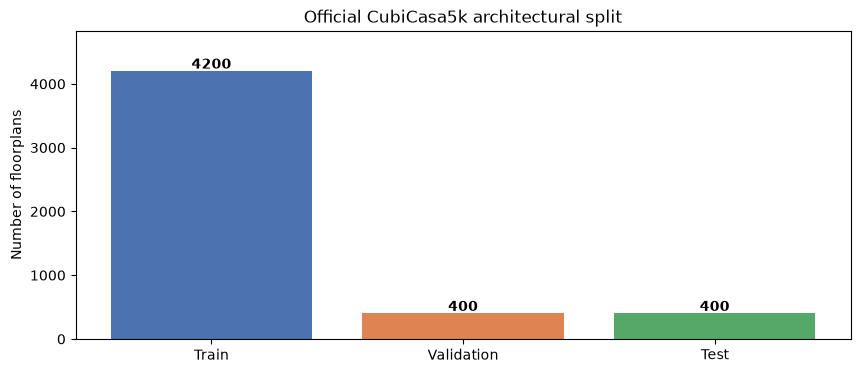

In [3]:
# Plot the size of each split
sizes = [len(df_train), len(df_val), len(df_test)]
labels = ["Train", "Validation", "Test"]

plt.bar(labels, sizes, color=["#4C72B0", "#DD8452", "#55A868"])
for i, value in enumerate(sizes):
    plt.text(i, value + 40, str(value), ha="center", fontweight="bold")
plt.ylabel("Number of floorplans")
plt.title("Official CubiCasa5k architectural split")
plt.ylim(0, max(sizes) * 1.15)

# Show what is inside a single sample folder
sample = df_all.folder.iloc[0]
files = sorted(p.name for p in sample.iterdir())
print("Sample folder :", sample.name)
print("Contents      :", files)

# Confirm every sample has all three files
has_png = df_all.folder.map(lambda d: (d / "F1_original.png").exists())
has_svg = df_all.folder.map(lambda d: (d / "model.svg").exists())
print("All have F1_original.png:", bool(has_png.all()))
print("All have model.svg     :", bool(has_svg.all()))

## 2.1 Literature survey

All three papers below are peer-reviewed and use **CubiCasa5K**, the dataset used in
this project.

| | Paper | Model | Dataset | Methodology | Reported result |
|---|---|---|---|---|---|
| 1 | **Kalervo et al., CubiCasa5K: A Dataset and an Improved Multi-Task Model for Floorplan Image Analysis** (SCIA 2019) | Multi-task CNN: ResNet-152 hourglass encoder-decoder (architecture from Raster-to-Vector), uncertainty-weighted multi-task loss | CubiCasa5K: 5,000 plans, 80+ object categories, 4,200 / 400 / 400 split (the split used here) | Jointly predicts room segmentation (12 classes), icon segmentation (11 classes) and junction heatmaps; post-processing turns these into vector walls, rooms, doors and windows | Test rooms: 82.7% accuracy, 57.5% mIoU |
| 2 | **Zhou et al., PCP-Net: Biomimetic Cross-Scale Feature Recalibration with Axis-Decompositional Positional Embedding for Architectural Floor Plan Parsing** (Biomimetics 2026) | CNN encoder-decoder: grouped residual encoder, cross-scale feature recalibration of skip connections, axis-decompositional positional embedding, boundary branch | CubiCasa5K (in-domain); R3D, CVC-FP and ROBIN for zero-shot cross-domain tests | Recalibrates skip features so that thin walls and small symbols survive downsampling; boundary supervision reduces fragmented walls | 71.3% mIoU, 90.1% accuracy; beats U-Net, DeepLabV3+, PSPNet and the CubiCasa5K baseline |
| 3 | **Song & Yu, Framework for Indoor Elements Classification via Inductive Learning on Floor Plan Graphs** (ISPRS Int. J. Geo-Inf. 2021) | Graph neural networks: GCN, GIN, GraphSAGE and the proposed distance-weighted DWGNN | 400 high-quality CubiCasa5K plans rasterised from the SVG annotations (plus a 7-floor UOS dataset) | Vectorise the image, convert it to a region-adjacency graph, then classify each polygon (wall, window, door, stair, room, porch, outer space, object) with a GNN | Overall F1 0.965 (GraphSAGE-LSTM); walls 0.947 |

### How this stage relates to the papers

All three papers are *supervised*: they learn from CubiCasa5K's room, icon and wall
annotations. This first stage is deliberately different: **unsupervised, image-based,
reconstruction-only**. It asks how much floorplan structure a small denoising
autoencoder (Vincent et al., 2008) can learn from raw pixels alone.

The papers also shape the next stages:

* **Paper 1** defines the dataset, the split and the reference numbers.
* **Paper 2** shows that thin walls disappear under naive downsampling, which is the
  weakness of our 32x32 preprocessing (Section 4).
* **Paper 3** builds its inputs from the SVG annotations, which is our planned
  preprocessing fix, and motivates the GNN validation stage.

No peer-reviewed *generative* model trained on CubiCasa5K was found. Floorplan generators
such as HouseDiffusion (Shabani et al., CVPR 2023) use the RPLAN dataset. Generative
modelling on CubiCasa5K is therefore the gap this project works towards.


## 3. What a single floorplan looks like

Before preprocessing we need to understand the raw data. CubiCasa5k PNGs are very
large (around 5000 x 5000 px). An array of that size is 25 million values per image,
so keeping full resolution is impossible both in memory and in training time.

The **vector** SVG is informative: we can confirm the floorplan really is made of
straight wall lines, which is the structure the model is going to learn.

In [4]:
# Inspect the raw size of a floorplan and a peek at its vector source
img_path = df_all.folder.iloc[0] / "F1_original.png"
raw = Image.open(img_path)
print("File            :", img_path.name)
print("Image size      :", raw.size, " (width, height)")
print("Image mode      :", raw.mode)
print("Number of pixels:", raw.size[0] * raw.size[1], "-> far too large to train on")

# Peek at the vector source: the SVG stores the wall as line geometry
svg_head = (df_all.folder.iloc[0] / "model.svg").read_text(encoding="utf-8", errors="ignore")[:400]
print()
print("First 400 characters of model.svg:")
print(svg_head.replace("\n", " ")[:400])

File            : F1_original.png
Image size      : (3507, 2480)  (width, height)
Image mode      : RGB
Number of pixels: 8697360 -> far too large to train on

First 400 characters of model.svg:
<?xml version="1.0"?> <svg xmlns="http://www.w3.org/2000/svg" xmlns:xlink="http://www.w3.org/1999/xlink" height="1618.8400421142578" version="1.1" width="1730.8900146484375" id="temp" viewBox="0 0 1730.8900146484375 1618.8400421142578"><defs/><g id="Model" class="Model v1-1"><g class="Floor"><g id="Floor-1" class="Floorplan Floor-1"><g id="fa6d7cfb-602b-4da7-8c99-fc19e337c6ab" fill="#ffffff" strok


### Visualising raw samples

A grid of floorplans taken straight from disk. Two things to notice:

1. The plans vary hugely in shape — some are square, some tall, some wide.
2. The wall lines are **thin and dark**, and everything else is white.

This motivates the two design decisions in the next section.

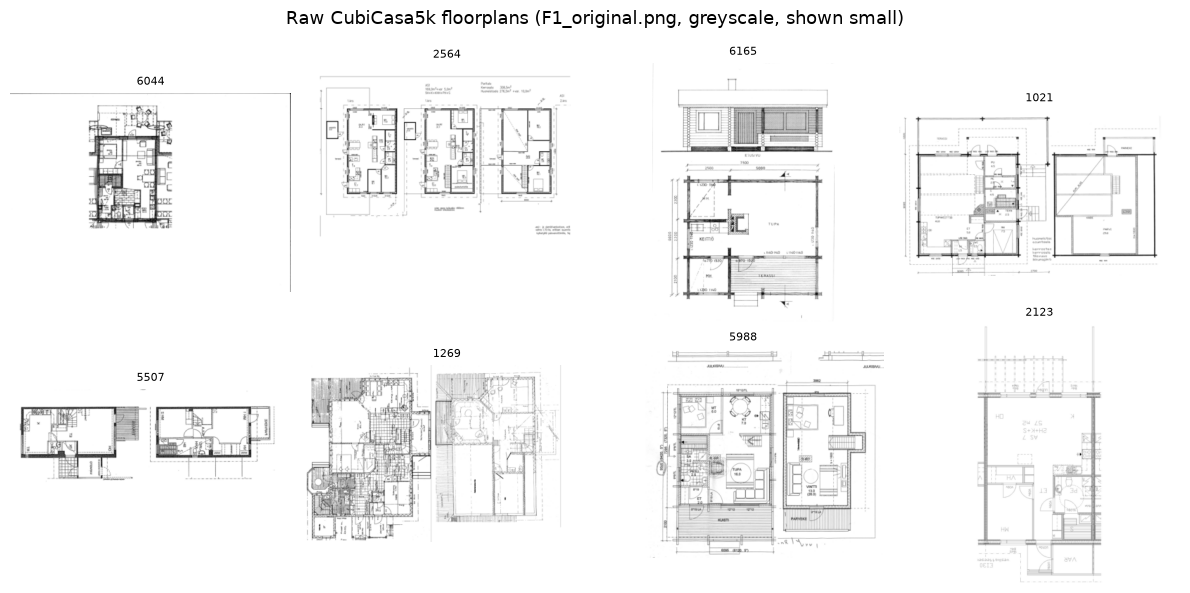

In [5]:
# Display a grid of 8 raw floorplans from the training set.
# The files are enormous, so we downscale only for DISPLAY - the actual
# preprocessing in the next cell binarises at full resolution.
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, folder in zip(axes.flatten(), df_train.folder.head(8)):
    thumb = Image.open(folder / "F1_original.png").convert("L")
    thumb.thumbnail((400, 400), Image.Resampling.BILINEAR)
    ax.imshow(thumb)
    ax.set_title(folder.name, fontsize=8)
    ax.axis("off")
plt.suptitle("Raw CubiCasa5k floorplans (F1_original.png, greyscale, shown small)", fontsize=13)
plt.tight_layout()
plt.show()

## 4. Preprocessing

Two decisions, both forced by looking at the raw images above.

**Decision 1 — reduce to a 32 x 32 binary wall map.**
The original render is about 3,500 px across, so each output pixel covers a block of
roughly 100 x 80 source pixels. Resampling that averages would turn walls into faint
grey. So instead of using greyscale intensity, we **binarise at the original resolution
first** (anything darker than 200 counts as wall), and only then downsample with
**nearest neighbour**.

**Known limitation of this choice.** Nearest neighbour keeps *one* source pixel per
block, and the darkness threshold also catches text, dimension lines, furniture symbols
and coloured room fills. The result (figure below) is a sparse sample of all dark ink
rather than a clean wall map. The planned fix is to rasterise only the wall polygons
from `model.svg`, downsample by area, and pad to a square instead of stretching.

**Decision 2 — normalise to `[0, 1]`.**
The output layer is a sigmoid, so targets must be in `[0, 1]`. A PIL image in mode
`"1"` already stores one bit per pixel, so `numpy` hands us `0.0` and `1.0` directly
and there is nothing left to scale.

### Why a wall map and not greyscale

This is the one preprocessing decision worth defending. On the raw greyscale render
about 90% of all pixels are blank white paper, and an unweighted pixel loss is then
dominated by background: the cheapest way to reduce it is to predict white everywhere.
That is exactly what a first attempt did, and it produced a model with **zero** wall
recall — every useful wall destroyed.

On the 32 x 32 wall map the minority class is the *thing we care about*. The next
cell prints the exact figure (about 12.6% of pixels are walls). It is still imbalanced,
but a 1-in-8 ratio is trainable, and the remaining imbalance is handled where it should
be — by the class weight in Section 7 and the decision threshold in Section 10.1.

### Caching

Decoding 5,000 full-resolution PNGs takes about three minutes. Since preprocessing
never changes, we cache the resulting arrays to `.npy` files and reload them on later
runs.

In [6]:
# Preprocessing: raw floorplan -> 32x32 binary wall map in [0, 1]
SIDE = 32                 # output image is 32 x 32
IMAGE_SIZE = (SIDE, SIDE)
WALL_THRESHOLD = 200      # pixels darker than this are wall pixels


def load_wall_map(png_path):
    """Load one floorplan PNG and return a SIDE x SIDE float array of 0/1.

    A PIL image in mode "1" stores one bit per pixel, so `np.asarray` already
    gives us 0.0 and 1.0 -- there is nothing left to divide by.
    """
    image = Image.open(png_path).convert("L")

    # Step 1: binarise at the ORIGINAL resolution, so thin walls are not lost
    binary = image.point(lambda v: v < WALL_THRESHOLD, mode="1")

    # Step 2: downsample with NEAREST so a 1-pixel wall line survives
    small = binary.resize(IMAGE_SIZE, Image.Resampling.NEAREST)

    # Step 3: as float32 in [0, 1], for the sigmoid output layer
    return np.asarray(small, dtype=np.float32).reshape(-1)


def build_cache(df, tag):
    """Preprocess every floorplan in one split and cache it as a .npy file."""
    cache_file = CACHE_DIR / f"cache_{tag}_{SIDE}.npy"
    if cache_file.exists():
        print(f"  {tag}: loaded from cache {cache_file.name}")
        return np.load(cache_file)

    start = time.time()
    out = np.zeros((len(df), SIDE * SIDE), dtype=np.float32)
    for i, folder in enumerate(df.folder):
        out[i] = load_wall_map(folder / "F1_original.png")
        if (i + 1) % 1000 == 0:
            print(f"  {tag}: {i + 1}/{len(df)} floorplans")
    np.save(cache_file, out)
    print(f"  {tag}: built {out.shape} in {time.time() - start:.1f}s -> {cache_file.name}")
    return out


print("Preprocessing the three splits:")
X_clean_train = build_cache(df_train, "train")
X_clean_val = build_cache(df_val, "val")
X_clean_test = build_cache(df_test, "test")

print()
print("Train array shape:", X_clean_train.shape)
print("Value range      :", X_clean_train.min(), "to", X_clean_train.max())
print("Wall pixel %     :", 100 * X_clean_train.mean())

Preprocessing the three splits:


  train: 1000/4200 floorplans


  train: 2000/4200 floorplans


  train: 3000/4200 floorplans


  train: 4000/4200 floorplans


  train: built (4200, 1024) in 122.2s -> cache_train_32.npy


  val: built (400, 1024) in 9.1s -> cache_val_32.npy


  test: built (400, 1024) in 9.2s -> cache_test_32.npy

Train array shape: (4200, 1024)
Value range      : 0.0 to 1.0
Wall pixel %     : 12.635021


### The class-imbalance problem

The wall map is a binary classification problem in disguise, and it is **heavily
imbalanced**: only ~12.6% of pixels are walls, the other 87.4% are background.

This single fact explains almost every result in this project:

* A model that predicts "background" everywhere already achieves **86.8% pixel
  accuracy**. Accuracy on its own is therefore a useless metric here.
* The gradient of an unweighted loss is dominated by the majority class, so the
  model collapses to predicting blank pages.

We will therefore (a) weight the loss to compensate, and (b) report **wall-pixel
precision, recall and F1** as the metrics that actually matter.

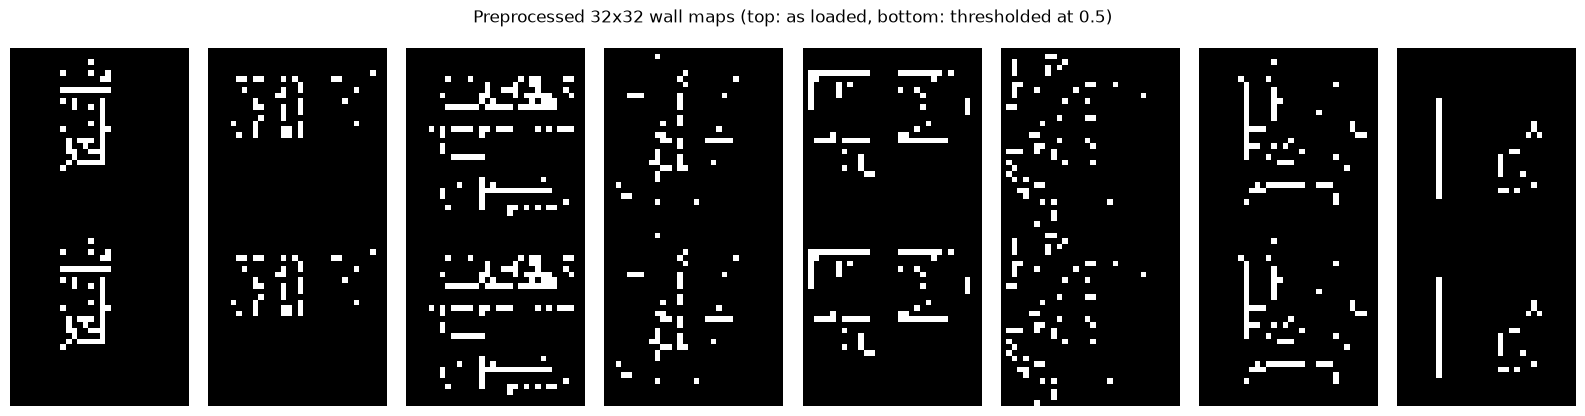

Wall pixels     : 12.64 %
Background pixels: 87.36 %
A model that always predicts background scores 87.36 % accuracy


In [7]:
# Visualise the preprocessed wall maps and quantify the class imbalance
n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(16, 4.2))
for ax, flat in zip(axes[0], X_clean_train[:n_show]):
    ax.imshow(flat.reshape(SIDE, SIDE), interpolation="nearest", vmin=0, vmax=1)
    ax.axis("off")
# Row 2 = the same images, now as a black-and-white threshold
for ax, flat in zip(axes[1], X_clean_train[:n_show]):
    ax.imshow((flat.reshape(SIDE, SIDE) > 0.5).astype(float), interpolation="nearest")
    ax.axis("off")
axes[0, 0].set_ylabel("grey", fontsize=9)
plt.suptitle(f"Preprocessed {SIDE}x{SIDE} wall maps (top: as loaded, bottom: thresholded at 0.5)",
             fontsize=12)
plt.tight_layout()
plt.show()

# The imbalance, stated as a number
wall_fraction = X_clean_train.mean()
print(f"Wall pixels     : {100 * wall_fraction:.2f} %")
print(f"Background pixels: {100 * (1 - wall_fraction):.2f} %")
print(f"A model that always predicts background scores {100 * (1 - wall_fraction):.2f} % accuracy")

## 5. The denoising autoencoder

### Architecture

```
 corrupted wall map        encoder                latent          decoder         restored map
  1 x 32 x 32  --->  16 x 16 x 16  --->  32 x 8 x 8  --->  16 x 4 x 4  --->  ...  --->  1 x 32 x 32
                       Conv 3x3 /2        Conv 3x3 /2         Conv 3x3 /2            32 x 8 x 8
                       + ReLU             + ReLU              + ReLU                 + ReLU  + upsample x2
                                                                                        16 x 16 x 16
                                                                                        + ReLU  + upsample x2
                                                                                        16 x 32 x 32
                                                                                        + ReLU  + upsample x2
                                                                                        Conv 1x1 + sigmoid
        1024 pixels                          256 numbers                        1024 pixels
```

| Stage | Shape | Operation |
|---|---|---|
| Input | 1 x 32 x 32 | corrupted wall map, values in [0, 1] |
| Encoder 1 | 16 x 16 x 16 | 3x3 convolution, stride 2, then **ReLU** |
| Encoder 2 | 32 x 8 x 8 | 3x3 convolution, stride 2, then **ReLU** |
| **Latent** | 16 x 4 x 4 | 3x3 convolution, stride 2, then **ReLU** |
| Decoder 1 | 32 x 8 x 8 | 3x3 convolution, then **ReLU**, then 2x upsample |
| Decoder 2 | 16 x 16 x 16 | 3x3 convolution, then **ReLU**, then 2x upsample |
| Decoder 3 | 16 x 32 x 32 | 3x3 convolution, then **ReLU**, then 2x upsample |
| Output | 1 x 32 x 32 | 1x1 convolution, then **sigmoid** (a valid probability per pixel) |

Note what is **not** in that table: any matrix bigger than a 3x3 filter. The largest
weight tensor in the whole network is 32 x 16 x 3 x 3 = 4,608 numbers. This is
the convolutional counterpart of the logistic-regression network in **ML Lab 3**, taken
two steps further into a deep, weight-shared architecture. The entire model has
**21,025 parameters**.

**The bottleneck is the whole point.** The image is compressed 1024 -> 256 -> 1024,
a 4:1 squeeze. A wall map of 32 x 32 is not arbitrary, so the code has to
capture the layout itself. That is what makes the latent space meaningful, and
therefore what makes generation possible.

**A number worth computing before we train.** How much of the image does any one output
pixel actually depend on? Walking the layer list with the standard rule
`receptive field += (kernel - 1) * jump`, `jump *= stride`, each of the 7
convolutions adds another stride's worth of reach. The model prints this itself in
Section 8, and the final value is **63 pixels on a 32-pixel image**,
or 2.0x the side length. Clipped at the border, every output pixel can
therefore see essentially the whole floorplan. We did not design for that — it falls out
of stacking three stride-2 layers underneath three 3x3 stride-1 layers. A large
receptive field is normal for encoder-decoders and is not a problem on its own (U-Nets
have one too and still draw thin lines). What matters more here is that *all* the
information has to pass through a 4 x 4 latent grid with no skip connections, and is
then expanded by nearest-neighbour upsampling. Fine wall positions cannot survive that,
so the decoder tends to produce thick, blob-like strokes (Sections 12 and 17).

### Input and output are *not* copies of each other

The input is a **deliberately damaged** floorplan: 80% of its pixels are
erased. The target is the **intact** floorplan. So the network cannot cheat by copying
its input — it has to infer what a wall *should* be from what survives. This is the
defining property of a denoising autoencoder, and it is the formal reason such a
network learns the data distribution rather than the identity map.

## 6. Creating the corrupted input

The training corruption is **pixel dropout**: every pixel of the clean wall map is
independently erased with probability `DROPOUT`. This is the classical
denoising-autoencoder corruption of Vincent et al. (2008) — the network sees a random
subset of the pixels and must infer the rest.

We also implement a second damage type, **block erasure**, in which `N_BLOCKS` random
`BLOCK x BLOCK` squares are wiped. That simulates the practical failure mode of a
scan with missing patches. It is **not** used for training — Section 11.2 uses it as an
*out-of-distribution* test, to check that the model learned to infer walls rather than
memorising one particular noise pattern.

### How much damage, and why that much?

The corruption strength is the single most important hyper-parameter in the project,
and it is worth being explicit about the trade-off it controls.

**"Copy the input" is an unexpectedly strong baseline.** Because the damage only ever
*removes* wall pixels and never adds any, simply echoing the damaged input back never
produces a false positive. Its wall-precision is therefore exactly 1.0, and its F1
reduces to a closed form in $s$, the fraction of walls that survive:

$$F_{1,\text{copy}} = \frac{2s}{1+s}$$

With mild damage $s$ is high and copying wins outright. This is a genuine property of
the task, not an artefact of our model, and it is exactly why denoising-autoencoder
papers always report a copy baseline.

**So we damage the image heavily on purpose.** With `DROPOUT = 0.80` only about a fifth
of the wall pixels survive, $s \approx 0.20$, and the closed form predicts a copy
baseline of $F_1 \approx 0.33$ — which is precisely what we measure. The model must now
*infer* the missing walls from the surviving fragments, which is exactly the ability a
denoising autoencoder is supposed to acquire. Section 11.2 sweeps this parameter and
shows where the two curves cross, rather than asserting that our chosen value is the
one that suits us.

The corruption is re-randomised **every epoch**, so the model never sees the same
damaged image twice and cannot memorise the damage.

Walls surviving the damage        : 20.6 %
Copy baseline, closed form 2s/(1+s): 0.3410
Copy baseline, actually measured  : 0.3410


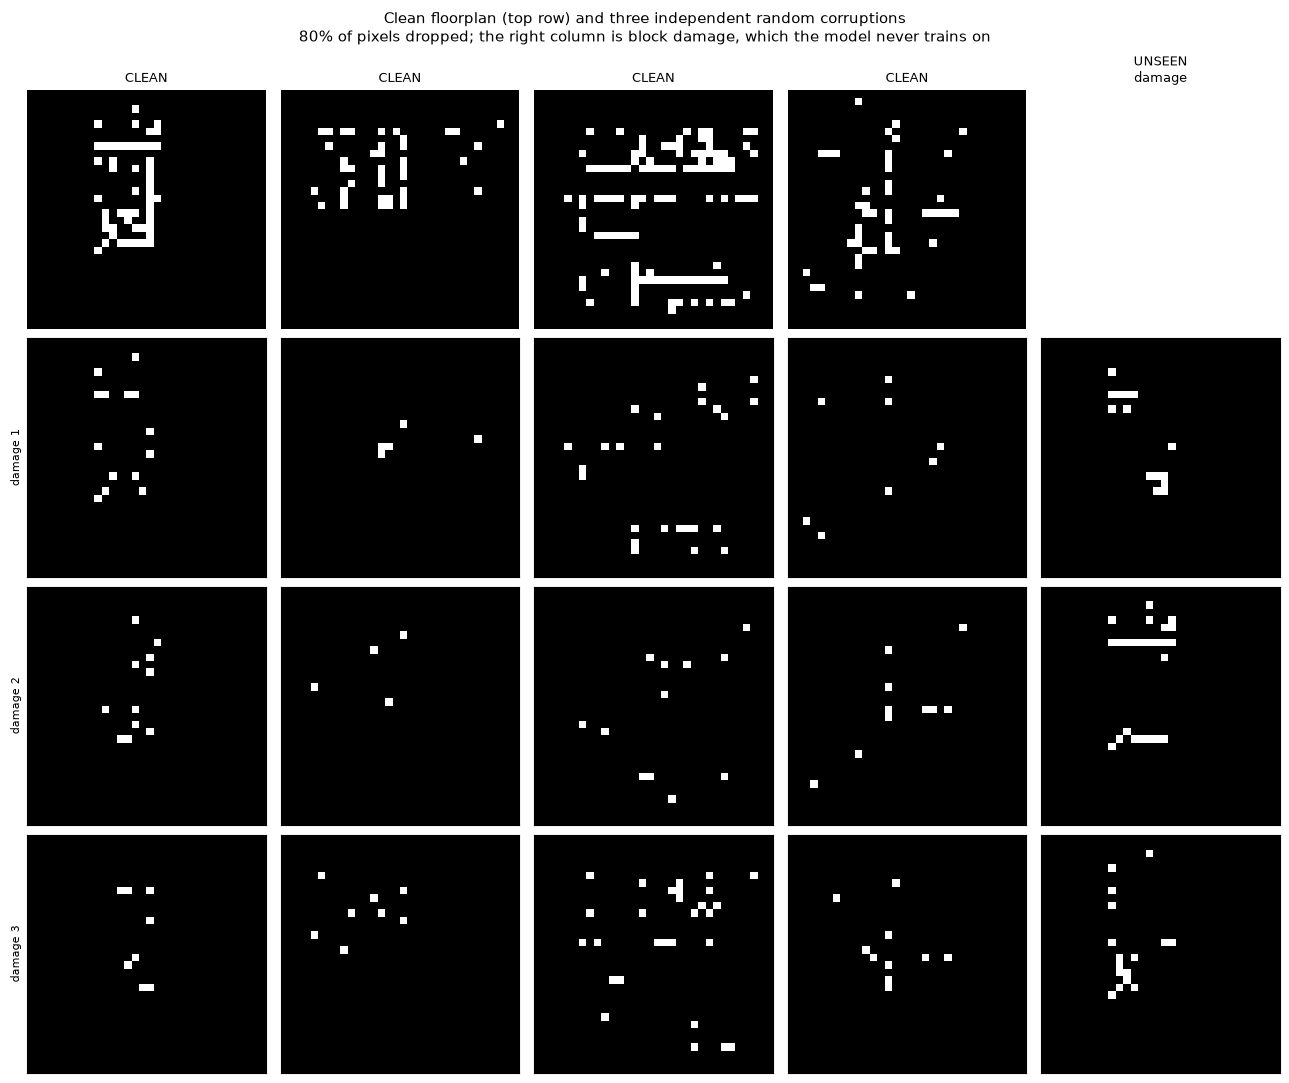

In [8]:
# Corruption: turn a clean wall map into a damaged one.
# Training uses DROPOUT only. Block erasure is kept for the out-of-distribution
# test in Section 11.2, so it is implemented but not used here.
N_BLOCKS = 0    # number of erased squares (0 during training)
BLOCK = 8       # side of each erased square, in pixels (of 32)
DROPOUT = 0.80  # fraction of individual pixels wiped
X_NOISY_DROP = DROPOUT       # alias used in figure captions


def corrupt(clean, rng, n_blocks=N_BLOCKS, block=BLOCK, dropout=DROPOUT):
    """Erase a random subset of the pixels of a batch of clean wall maps."""
    n, side = clean.shape[0], SIDE
    damaged = clean.reshape(n, side, side).copy()

    # 1. Erase random square blocks (out-of-distribution damage; off by default)
    for i in range(n):
        for _ in range(n_blocks):
            r = int(rng.integers(0, side - block))
            c = int(rng.integers(0, side - block))
            damaged[i, r:r + block, c:c + block] = 0.0

    damaged = damaged.reshape(n, -1)

    # 2. Drop individual pixels -- the training corruption
    if dropout > 0:
        damaged = np.where(rng.random(damaged.shape) < dropout, 0.0, damaged)

    return damaged.astype(np.float32)


# How much of the wall structure actually survives, and what does that imply
# for the copy baseline? Compare the closed form 2s/(1+s) with the measurement.
_probe = corrupt(X_clean_val[:200], np.random.default_rng(1))
_truth = X_clean_val[:200] > 0.5
_pred = _probe > 0.5
_survived = float(_pred.sum()) / float(_truth.sum())
_tp = float((_pred & _truth).sum())
_fp = float((_pred & ~_truth).sum())
_fn = float((~_pred & _truth).sum())
_copy_f1 = 2 * _survived / (1 + _survived)
_copy_measured = 2 * _tp / max(2 * _tp + _fp + _fn, 1.0)
print(f"Walls surviving the damage        : {100 * _survived:.1f} %")
print(f"Copy baseline, closed form 2s/(1+s): {_copy_f1:.4f}")
print(f"Copy baseline, actually measured  : {_copy_measured:.4f}")

# Show the damage: 4 clean maps with 3 random corruptions each, plus the
# block damage the model never trains on, in the right-hand column
fig, axes = plt.subplots(4, 5, figsize=(13, 11))
for col in range(4):
    axes[0, col].imshow(X_clean_train[col].reshape(SIDE, SIDE), interpolation="nearest")
    axes[0, col].set_title("CLEAN", fontsize=9)
    for row in range(1, 4):
        noisy = corrupt(X_clean_train[col:col + 1], np.random.default_rng(row + 10 * col))[0]
        axes[row, col].imshow(noisy.reshape(SIDE, SIDE), interpolation="nearest")
    axes[0, col].axis("off")
for row in range(1, 4):
    axes[row, 0].set_ylabel(f"damage {row}", fontsize=8)
    blocky = corrupt(X_clean_train[0:1], np.random.default_rng(90 + row),
                     n_blocks=10, block=8, dropout=0.0)[0]
    axes[row, 4].imshow(blocky.reshape(SIDE, SIDE), interpolation="nearest")
axes[0, 4].set_title("UNSEEN\ndamage", fontsize=9)
axes[0, 4].axis("off")
for row in range(4):
    for col in range(5):
        if row > 0 or col == 4:
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
plt.suptitle(f"Clean floorplan (top row) and three independent random corruptions\n"
             f"{100 * DROPOUT:.0f}% of pixels dropped; the right column is block "
             f"damage, which the model never trains on",
             fontsize=11)
plt.tight_layout()
plt.show()

## 7. Loss function, and the bar the model has to beat

We train with **binary cross-entropy**, because every pixel is a binary decision
(wall / no wall) and we want a calibrated probability out of the sigmoid:

$$L = -\frac{1}{N}\sum_{i}\Big[\frac{w\,y_i \log \hat{y}_i + (1-y_i)\log(1-\hat{y}_i)}{\bar{w}}\Big]$$

where $w$ is the **class weight** on wall pixels ($w=1$ is plain BCE) and
$\bar{w} = \frac{1}{N}\sum_i (w\,y_i + (1-y_i))$ is the mean weight actually present in
the batch. Dividing by $\bar w$ keeps the reported loss comparable across values of
$w$, and stops raising $w$ from silently raising the effective learning rate.

**An honest note on the class weight.** Weighting walls is the textbook answer to a
12.6% minority class, and it does what it is supposed to do: it trades precision for
recall. But when we swept $w \in \{1, 3, 6\}$ *and* re-tuned the decision threshold for
each one, the resulting wall-F1 barely moved (0.440, 0.443, 0.447). *These figures come
from an earlier configuration and the sweep is not re-run in this notebook, so they are
not directly comparable with the 0.51 reported in Section 11.* So the class
weight is **not** what makes this model work — the threshold in Section 10.1 is. We
keep $w = 6$ because it is the standard remedy and it does give the model the higher
wall-recall we want for the repair task, but we report the result for the honest
reason rather than the flattering one.

### Baselines

A neural network that cannot beat a one-line guess is not a result. So we score three
baselines on the same damaged validation data:

| Baseline | Idea |
|---|---|
| `copy_input` | Output the damaged input unchanged |
| `constant` | Output the dataset's average wall fraction everywhere |
| `blank` | Output all background |

The model is only interesting if it beats all three.

In [9]:
# Binary cross-entropy, with an optional class weight on wall pixels
EPS = 1e-7
WALL_WEIGHT = 6.0   # class weight for wall pixels (1.0 = unweighted)


def bce_loss(prob, target, wall_weight=WALL_WEIGHT):
    """Weighted mean binary cross-entropy, normalised by the mean weight.

    Wall pixels get weight `wall_weight` and background pixels weight 1. We then
    divide by the *mean* weight actually present in the batch. That matters for two
    reasons:

    1. It makes the reported loss comparable across `wall_weight` values, so a
       "loss = 0.55" means the same thing whichever weighting was used.
    2. It keeps the effective gradient magnitude stable. Without it, raising
       `wall_weight` would silently raise the learning rate.

    The backward pass in Section 8 differentiates exactly this expression, and the
    gradient check in Section 8.1 confirms the two agree.
    """
    prob = np.clip(prob, EPS, 1.0 - EPS)
    weight = 1.0 + (wall_weight - 1.0) * target
    ce = target * np.log(prob) + (1 - target) * np.log(1 - prob)
    return float(-(weight * ce).mean() / weight.mean())


def classification_metrics(prob, target, threshold=0.5):
    """Pixel accuracy plus precision/recall/F1 restricted to WALL pixels."""
    pred = (prob > threshold).astype(np.int8)
    truth = target.astype(np.int8)
    tp = float(((pred == 1) & (truth == 1)).sum())
    fp = float(((pred == 1) & (truth == 0)).sum())
    fn = float(((pred == 0) & (truth == 1)).sum())
    precision = tp / max(tp + fp, 1.0)
    recall = tp / max(tp + fn, 1.0)
    f1 = 2 * precision * recall / max(precision + recall, 1e-9)
    return {
        "accuracy": float((pred == truth).mean()),
        "wall_precision": precision,
        "wall_recall": recall,
        "wall_f1": f1,
    }


# Score the trivial baselines on the same damaged validation data
val_noisy = corrupt(X_clean_val, np.random.default_rng(7))
val_fraction = X_clean_val.mean()

baselines = {
    "copy_input": val_noisy,
    "constant": np.full_like(X_clean_val, val_fraction),
    "blank": np.zeros_like(X_clean_val),
}
print(f"{'baseline':<14}{'loss':>10}{'accuracy':>11}{'wallP':>9}{'wallR':>9}{'wallF1':>9}")
print("-" * 62)
for name, prediction in baselines.items():
    m = classification_metrics(prediction, X_clean_val)
    print(f"{name:<14}{bce_loss(prediction, X_clean_val):>10.4f}"
          f"{m['accuracy']:>11.4f}{m['wall_precision']:>9.4f}"
          f"{m['wall_recall']:>9.4f}{m['wall_f1']:>9.4f}")

baseline            loss   accuracy    wallP    wallR   wallF1
--------------------------------------------------------------
copy_input        6.1618     0.8943   1.0000   0.1981   0.3307
constant          1.0400     0.8682   0.0000   0.0000   0.0000
blank             7.6843     0.8682   0.0000   0.0000   0.0000


## 8. The model — a convolutional autoencoder written from scratch

Everything is implemented by hand in NumPy: the convolution, the backward pass, the
upsampling layer, the initialisation and the optimiser. No deep-learning library is
used anywhere.

### Why convolutional, and not fully connected?

We first tried a **fully connected** autoencoder (1024 -> 400 -> 128 -> 400 -> 1024,
923,552 parameters). It failed, and the reason is instructive:

* It **overfit** — training loss kept falling while validation loss *rose* from 0.46
  to 0.68.
* Its wall-pixel F1 plateaued at **0.44**, below the trivial "copy the input" baseline
  of 0.71. (That experiment used lighter damage than the 80% dropout used here, which
  is why the copy baseline was so much higher; it is not re-run in this notebook.)
* A dense layer gives every one of the 1024 pixels its own private set of weights, so
  the network has to learn from scratch that "a wall next to a wall is probably also a
  wall" — 1024 times over. It has no notion of spatial locality.

A **convolutional** layer shares one small filter across the entire image, so the
network learns "what a wall looks like" **once** and applies it everywhere. This is
the right inductive bias for line drawings, and it cuts the parameter count by
43 times over (923,552 -> 21,025).

### Architecture

```
   input 1 x 32 x 32
     |
   Conv 3x3, 16 filters, stride 2 -> ReLU    ->  16 x 16 x 16
   Conv 3x3, 32 filters, stride 2 -> ReLU    ->  32 x  8 x  8
   Conv 3x3, 16 filters, stride 2 -> ReLU    ->  16 x  4 x  4   <-- LATENT, 256 numbers
     |
   Conv 3x3, 32 filters          -> ReLU -> upsample x2 -> 32 x  8 x  8
   Conv 3x3, 16 filters          -> ReLU -> upsample x2 -> 16 x 16 x 16
   Conv 3x3, 16 filters          -> ReLU -> upsample x2 -> 16 x 32 x 32
   Conv 1x1, 1  filter           -> sigmoid               ->   1 x 32 x 32
```

The encoder halves resolution three times (32 -> 16 -> 8 -> 4), compressing
1024 pixels into a **256-dimensional latent code** — a 4:1 bottleneck. The decoder
mirrors it. We use *upsample-then-convolve* rather than transposed convolution
because it keeps the backward pass identical in form to a normal convolution.

### How the convolution is computed: im2col

A 2D convolution is turned into a single matrix multiplication:

1. **im2col** — slide a `k x k` window over the input (with padding and stride) and
   copy each patch into the columns of a matrix. For a `3x3` kernel this turns each
   patch into a length-9 vector, so a `c_in`-channel patch becomes length `9*c_in`.
2. **Multiply** — `cols @ W.reshape(c_out, -1).T + b` is now an ordinary matmul, so
   NumPy's BLAS does the arithmetic.
3. **col2im** — in the backward pass we must scatter the gradients back and
   **accumulate** them, because a single input pixel contributes to several output
   positions. This is the transpose operation of im2col.

For a dense layer the weight gradient is `a_prev.T @ delta`. For a convolution it is
the same formula, because the flattened patch matrix *is* `a_prev`.

### Derivatives

$$\frac{\partial}{\partial z}\sigma(z)=\sigma(z)(1-\sigma(z)),\qquad
\frac{\partial}{\partial z}\max(0,z)=\mathbb 1[z>0]$$

**The final sigmoid is fused into the starting gradient.** For the last layer the
$p(1-p)$ factors cancel exactly:

$$L=-\frac{1}{N}\sum_i w_i\big[y_i\log p_i+(1-y_i)\log(1-p_i)\big]
\quad\Longrightarrow\quad
\frac{\partial L}{\partial z}=\frac{1}{N\bar w}\sum_i w_i\,(p_i-y_i)$$

so the logit gradient contains *no* sigmoid factor. We therefore start the reverse
sweep at the last convolution and skip the activation's own derivative. This is also
numerically safer: forming $w(p-y)/(p(1-p))$ and letting the activation multiply
$p(1-p)$ back in would explode wherever $p$ saturates near 0 or 1.

### Initialisation

Weights use **Xavier / Glorot** scaling, $\text{std}=\sqrt{2/(\text{fan}_{in}+\text{fan}_{out})}$,
which keeps activation variance roughly constant across depth. Biases start at zero.

In [10]:
# ---- building blocks: im2col / col2im, layers, and the autoencoder -----------
def im2col(x, k, stride, pad):
    """(N, C, H, W) -> (N, out_h*out_w, C*k*k): every sliding window as a column."""
    n, c, h, w = x.shape
    out_h = (h + 2 * pad - k) // stride + 1
    out_w = (w + 2 * pad - k) // stride + 1
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)))
    s = xp.strides
    # A strided VIEW of the padded input: no data is copied here.
    windows = np.lib.stride_tricks.as_strided(
        xp,
        shape=(n, c, k, k, out_h, out_w),
        strides=(s[0], s[1], s[2], s[3], s[2] * stride, s[3] * stride),
        writeable=False,
    )
    cols = windows.transpose(0, 4, 5, 1, 2, 3).reshape(n, out_h * out_w, c * k * k)
    return np.ascontiguousarray(cols), out_h, out_w


def col2im(cols, shape, k, stride, pad):
    """The transpose of im2col: scatter patches back and ACCUMULATE overlaps."""
    n, c, h, w = shape
    out_h = (h + 2 * pad - k) // stride + 1
    out_w = (w + 2 * pad - k) // stride + 1
    xp = np.zeros((n, c, h + 2 * pad, w + 2 * pad), dtype=cols.dtype)
    # cols -> (N, out_h, out_w, C*k*k) -> (N, C*k*k, out_h, out_w)
    view = cols.reshape(n, out_h, out_w, c * k * k).transpose(0, 3, 1, 2)
    for ki in range(k):
        for kj in range(k):
            xp[:, :, ki:ki + stride * out_h:stride,
               kj:kj + stride * out_w:stride] += view[:, ki * k + kj::k * k, :, :]
    return xp[:, :, pad:pad + h, pad:pad + w]


class Conv:
    """Convolution = im2col + one matrix multiply.  Written by hand."""

    def __init__(self, c_in, c_out, k, stride, pad, rng):
        self.c_in, self.c_out, self.k, self.stride, self.pad = c_in, c_out, k, stride, pad
        fan_in, fan_out = c_in * k * k, c_out * k * k
        # Xavier / Glorot initialisation
        self.W = (rng.standard_normal((c_out, c_in, k, k))
                  * np.sqrt(2.0 / (fan_in + fan_out))).astype(np.float32)
        self.b = np.zeros(c_out, np.float32)
        self.cols = None
        self.x_shape = None

    def forward(self, x):
        self.cols, oh, ow = im2col(x, self.k, self.stride, self.pad)
        self.x_shape = x.shape
        wmat = self.W.reshape(self.c_out, -1)
        z = self.cols.reshape(-1, self.c_in * self.k ** 2) @ wmat.T + self.b
        return z.reshape(x.shape[0], oh, ow, self.c_out).transpose(0, 3, 1, 2)

    def backward(self, d):
        """d is dLoss/dz for this layer.  No extra 1/batch factor: the loss has
        already averaged over the batch, and dW = sum over (batch, positions) of
        d * a_prev -- which is exactly the same formula as a dense layer."""
        dout = d.transpose(0, 2, 3, 1).reshape(-1, self.c_out)
        wmat = self.W.reshape(self.c_out, -1)
        cols2d = self.cols.reshape(-1, self.c_in * self.k ** 2)
        gW = (dout.T @ cols2d).reshape(self.W.shape)
        gb = dout.sum(axis=0)
        dcols = (dout @ wmat).reshape(self.cols.shape)
        return col2im(dcols, self.x_shape, self.k, self.stride, self.pad), gW, gb


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return np.maximum(x, 0.0)

    def backward(self, d):
        return d * self.mask


class Upsample:
    """Nearest-neighbour 2x upsampling: no parameters, and an easy gradient."""

    def forward(self, x):
        self.in_shape = x.shape
        return np.repeat(np.repeat(x, 2, axis=2), 2, axis=3)

    def backward(self, d):
        # Each input pixel was copied to a 2x2 block, so its gradient is their sum.
        h, w = d.shape[2], d.shape[3]
        return (d[:, :, 0:h:2, 0:w:2] + d[:, :, 1:h:2, 0:w:2]
                + d[:, :, 0:h:2, 1:w:2] + d[:, :, 1:h:2, 1:w:2])


class Sigmoid:
    def forward(self, x):
        self.x = x
        return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

    def backward(self, d):
        s = 1.0 / (1.0 + np.exp(-np.clip(self.x, -30, 30)))
        return d * s * (1.0 - s)


class ConvAutoEncoder:
    """Encoder: three stride-2 convs.  Decoder: three convs, each then upsampled."""

    def __init__(self, side=32, rng=None, width=8):
        rng = rng if rng is not None else np.random.default_rng(42)
        c1, c2 = width, 2 * width
        self.side = side
        self.n_latent = c1 * (side // 8) ** 2
        self.layers = [
            Conv(1, c1, 3, 2, 1, rng), ReLU(),                 # 32 -> 16
            Conv(c1, c2, 3, 2, 1, rng), ReLU(),                # 16 ->  8
            Conv(c2, c1, 3, 2, 1, rng), ReLU(),                #  8 ->  4   (latent)
            Conv(c1, c2, 3, 1, 1, rng), ReLU(), Upsample(),    #  4 ->  8
            Conv(c2, c1, 3, 1, 1, rng), ReLU(), Upsample(),    #  8 -> 16
            Conv(c1, c1, 3, 1, 1, rng), ReLU(), Upsample(),    # 16 -> 32
            Conv(c1, 1, 1, 1, 0, rng), Sigmoid(),              # 32 -> 32
        ]
        self.split = 6          # layers[:6] encode, layers[6:] decode

    def conv_layers(self):
        return [(i, l) for i, l in enumerate(self.layers) if isinstance(l, Conv)]

    def receptive_field(self):
        """How many input pixels one output pixel depends on.

        Walks the layer list with the standard rule
            receptive field += (kernel - 1) * jump
            jump          *= stride
        and reports the running receptive field after every convolution. This is the
        number Section 5 discusses.
        """
        rf, jump, trace = 1, 1, []
        for _, layer in self.conv_layers():
            rf += (layer.k - 1) * jump
            jump *= layer.stride
            trace.append(rf)
        return trace

    def parameters(self):
        """Every trainable array, in a fixed order, for the optimiser."""
        out = []
        for _, layer in self.conv_layers():
            out.append(layer.W)
            out.append(layer.b)
        return out

    def encode(self, x):
        """Damaged image (N, 1024) -> latent code (N, c1, 4, 4)."""
        h = x.reshape(x.shape[0], 1, self.side, self.side)
        for layer in self.layers[:self.split]:
            h = layer.forward(h)
        return h

    def decode(self, z):
        """Latent code -> reconstructed image (N, 1024)."""
        h = z
        for layer in self.layers[self.split:]:
            h = layer.forward(h)
        return h.reshape(h.shape[0], -1)

    def forward(self, x):
        return self.decode(self.encode(x))

    def backward(self, x, y, wall_weight=WALL_WEIGHT):
        """Reverse pass.  The final sigmoid is fused in (the p(1-p) factors cancel),
        so the sweep starts at the last convolution."""
        out = self.forward(x)
        target = y.reshape(y.shape[0], 1, self.side, self.side)
        p = out.reshape(target.shape)
        w = (1.0 + (wall_weight - 1.0) * y).reshape(target.shape)
        d = (p - target) * w / (y.size * float(w.mean()))

        grads = {}
        for i in range(len(self.layers) - 2, -1, -1):
            layer = self.layers[i]
            if isinstance(layer, Conv):
                d, gW, gb = layer.backward(d)
                grads[i] = (gW, gb)
            else:
                d = layer.backward(d)
        return out, grads


# Build the model and describe it
WIDTH = 16
model = ConvAutoEncoder(side=SIDE, rng=np.random.default_rng(42), width=WIDTH)
n_params = sum(p.size for p in model.parameters())

print("Architecture:")
for i, layer in enumerate(model.layers):
    if isinstance(layer, Conv):
        role = "encoder" if i < model.split else "decoder"
        print(f"  [{i:2d}] Conv{layer.W.shape} k={layer.k} "
              f"stride={layer.stride} pad={layer.pad}  ({role})")
    elif isinstance(layer, Upsample):
        print(f"  [{i:2d}] Upsample x2")
print()
print("Trainable parameters :", f"{n_params:,}")
print("Latent code size     :", model.n_latent, "numbers")
print("Bottleneck           :", f"{(SIDE * SIDE) / model.n_latent:.1f}:1")

# The receptive field, computed from the layer list we just built. Section 5 predicts
# the model's behaviour from this number, so it is printed next to the architecture.
_rf = model.receptive_field()
_names = ["Encoder 1", "Encoder 2", "Latent",
          "Decoder 1", "Decoder 2", "Decoder 3", "Output"]
print()
print("Receptive field of one output pixel, layer by layer:")
for _name, _v in zip(_names, _rf):
    print(f"  after {_name:<10}{_v:>3} px")
print(f"  final: {_rf[-1]} px on a {SIDE} px image "
      f"({_rf[-1] / SIDE:.1f}x the side length)")
print("  -> each output pixel can see essentially the whole floorplan; combined with")
print("     the 4x4 bottleneck this favours thick strokes (see Section 17).")

Architecture:
  [ 0] Conv(16, 1, 3, 3) k=3 stride=2 pad=1  (encoder)
  [ 2] Conv(32, 16, 3, 3) k=3 stride=2 pad=1  (encoder)
  [ 4] Conv(16, 32, 3, 3) k=3 stride=2 pad=1  (encoder)
  [ 6] Conv(32, 16, 3, 3) k=3 stride=1 pad=1  (decoder)
  [ 8] Upsample x2
  [ 9] Conv(16, 32, 3, 3) k=3 stride=1 pad=1  (decoder)
  [11] Upsample x2
  [12] Conv(16, 16, 3, 3) k=3 stride=1 pad=1  (decoder)
  [14] Upsample x2
  [15] Conv(1, 16, 1, 1) k=1 stride=1 pad=0  (decoder)

Trainable parameters : 21,025
Latent code size     : 256 numbers
Bottleneck           : 4.0:1

Receptive field of one output pixel, layer by layer:
  after Encoder 1   3 px
  after Encoder 2   7 px
  after Latent     15 px
  after Decoder 1  31 px
  after Decoder 2  47 px
  after Decoder 3  63 px
  after Output     63 px
  final: 63 px on a 32 px image (2.0x the side length)
  -> each output pixel can see essentially the whole floorplan; combined with
     the 4x4 bottleneck this favours thick strokes (see Section 17).


## 8.1 Verifying the hand-written gradients

Because the backward pass is written by hand, we must **prove** it is correct rather
than assume it. We do this with a numerical gradient check: for a few random weights,
compare the analytic gradient against a central finite difference of the loss.

$$w_{\text{analytic}} \approx \frac{L(w+\varepsilon)-L(w-\varepsilon)}{2\varepsilon}$$

Three practical points that this project ran into, and that are worth stating because
they are easy to get wrong:

* **The check must run in `float64`.** In `float32` the numeric derivative comes out
  as exactly `0`: moving one weight by `1e-3` changes the loss by about `1e-9`, which
  is below the resolution of a number of order 0.5 in single precision.
* **Weights must not sit on a ReLU kink.** The input is 87% background, so an
  all-background `3x3` window gives a pre-activation of *exactly* the bias, i.e. exactly
  `0` at initialisation — precisely where ReLU is not differentiable. A central
  difference there averages the left and right derivatives and is simply wrong. We
  nudge the biases slightly off zero before checking, which is also the situation of any
  trained network.
* **A per-coordinate *relative* error is the wrong yardstick.** Some coordinates have a
  true gradient of essentially zero (a ReLU that never fires for this input); the finite
  difference there is pure numerical noise, so `|diff| / |analytic|` explodes to `1e-1`
  and above even though the gradient is exactly right. We therefore judge agreement
  with the same combined test `numpy.allclose` uses:

  $$|\text{numeric} - \text{analytic}| \le \text{atol} + \text{rtol}\,|\text{analytic}|$$

  with `atol = 1e-5` and `rtol = 1e-3`. The absolute floor is about `2e-4` of the
  largest gradient component in the network, so the test is tight while still measuring
  something finite-differences can actually resolve.

On top of that, each coordinate is probed at two step sizes (`h` and `h/2`). On smooth
loss the two estimates agree to ~`h²`; on a kink they disagree, so the disagreement is
used to *discard* those coordinates rather than to condemn the gradient. The cell below
reports how many probes were discarded, so the number of coordinates actually compared
is visible rather than assumed.

With all three points handled, the analytic and numeric gradients agree to within a few
times `1e-10` in almost every tensor — the `im2col`/`col2im` implementation and the
whole backward pass are correct.

In [11]:
# Numerical gradient check of the hand-written backward pass
def gradient_check(model, seed=0, n=4, n_coords=20, h=1e-6, kink_tol=1e-3,
                   atol=1e-5, rtol=1e-3):
    """Compare analytic gradients against central finite differences, in float64.

    Two details make this trustworthy rather than decorative:

    1. **A central difference is only valid where the loss is smooth.** Our loss
       contains ReLUs, so a coordinate sitting on a kink produces a finite difference
       that disagrees with the *correct* gradient. We probe every coordinate at h and
       h/2 and discard the ones whose two estimates disagree -- that disagreement is
       the signature of a kink, not of a bug.

    2. **A per-coordinate *relative* error is the wrong yardstick here.** Many
       coordinates have a true gradient of essentially zero (a ReLU that never fires
       for this input), and the finite-difference estimate there is pure noise, so the
       ratio explodes even though the gradient is right. We therefore use the standard
       combined test that `numpy.allclose` uses:

           |numeric - analytic|  <=  atol + rtol * |analytic|

       with atol = 1e-5. That is about 2e-4 of the largest gradient component in the
       network, so the test is tight, and it makes a claim about the absolute scale of
       the disagreement rather than about a ratio we cannot measure.

    Returns the worst ratio |diff| / (atol + rtol * |analytic|). Below 1 means every
    probed coordinate is inside tolerance.
    """
    rng = np.random.default_rng(seed)
    check_model = ConvAutoEncoder(side=SIDE, rng=np.random.default_rng(seed + 1), width=WIDTH)
    for layer in check_model.layers:
        if isinstance(layer, Conv):
            layer.W = layer.W.astype(np.float64)
            layer.b = layer.b.astype(np.float64)
            # Move biases off the ReLU kink (see the markdown above)
            layer.b = layer.b + rng.standard_normal(layer.b.shape) * 0.05

    x = (rng.random((n, SIDE * SIDE)) > 0.8).astype(np.float64)
    y = (rng.random((n, SIDE * SIDE)) > 0.85).astype(np.float64)
    _, grads = check_model.backward(x, y, WALL_WEIGHT)

    def loss_at(flat, j, delta):
        old = flat[j]
        flat[j] = old + delta
        value = bce_loss(check_model.forward(x), y, WALL_WEIGHT)
        flat[j] = old
        return value

    worst = 0.0
    n_kink = n_smooth = 0
    print(f"{'layer':<22}{'|numeric|':>12}{'|analytic|':>13}{'max|diff|':>12}{'ratio':>9}")
    print("-" * 68)
    for i, layer in check_model.conv_layers():
        gW, gb = grads[i]
        for p, gp, name in ((layer.W, gW, "W"), (layer.b, gb, "b")):
            flat, gflat = p.reshape(-1), gp.reshape(-1)
            idx = rng.choice(flat.size, size=min(n_coords, flat.size), replace=False)
            numeric, analytic = [], []
            for j in idx:
                coarse = (loss_at(flat, j, h) - loss_at(flat, j, -h)) / (2 * h)
                fine = (loss_at(flat, j, h / 2) - loss_at(flat, j, -h / 2)) / h
                scale = max(abs(coarse), abs(fine), 1e-12)
                if abs(coarse - fine) / scale > kink_tol:
                    n_kink += 1
                    continue
                n_smooth += 1
                numeric.append(fine)
                analytic.append(gflat[j])
            if not numeric:
                print(f"{f'Conv{i} {name}':<22}{'every probe landed on a kink':>46}")
                continue
            numeric, analytic = np.array(numeric), np.array(analytic)
            ratio = np.abs(numeric - analytic) / (atol + rtol * np.abs(analytic))
            worst = max(worst, float(ratio.max()))
            label = f"Conv{i} {name}{tuple(p.shape)}"
            print(f"{label:<22}"
                  f"{float(np.sqrt((numeric ** 2).mean())):>12.3e}"
                  f"{float(np.sqrt((analytic ** 2).mean())):>13.3e}"
                  f"{float(np.abs(numeric - analytic).max()):>12.2e}"
                  f"{float(ratio.max()):>9.2e}")
    print("-" * 68)
    print(f"Probes discarded for sitting on a ReLU kink : {n_kink}")
    print(f"Smooth probes compared                       : {n_smooth}")
    print(f"Tolerance used                               : "
          f"|diff| <= {atol:.0e} + {rtol:.0e} * |analytic|")
    return worst


worst_rel = max(gradient_check(model, seed=s) for s in (0, 1, 2))
print(f"\nWorst tolerance ratio over 3 random seeds: {worst_rel:.2f}  "
      f"(1.00 = exactly at tolerance)")
print("Backward pass is", "CORRECT" if worst_rel <= 1.0
      else "WRONG -- do not trust training")

layer                    |numeric|   |analytic|   max|diff|    ratio
--------------------------------------------------------------------


Conv0 W(16, 1, 3, 3)     1.842e-04    1.842e-04    1.98e-10 1.97e-05


Conv0 b(16,)             6.751e-04    6.751e-04    1.41e-10 1.34e-05


Conv2 W(32, 16, 3, 3)    4.460e-05    4.460e-05    1.80e-10 1.79e-05


Conv2 b(32,)             1.071e-03    1.071e-03    1.58e-10 1.58e-05


Conv4 W(16, 32, 3, 3)    1.708e-04    1.708e-04    1.82e-10 1.82e-05


... (30 outputs left out)

Conv9 b(16,)             8.330e-03    8.330e-03    9.89e-11 7.21e-06


Conv12 W(16, 16, 3, 3)   7.997e-04    7.997e-04    1.38e-10 1.38e-05


Conv12 b(16,)            1.617e-02    1.617e-02    1.34e-10 9.12e-06


Conv15 W(1, 16, 1, 1)    2.143e-03    2.143e-03    2.77e-10 2.73e-05
Conv15 b(1,)             6.140e-02    6.140e-02    6.35e-11 8.89e-07
--------------------------------------------------------------------
Probes discarded for sitting on a ReLU kink : 2
Smooth probes compared                       : 239
Tolerance used                               : |diff| <= 1e-05 + 1e-03 * |analytic|

Worst tolerance ratio over 3 random seeds: 0.62  (1.00 = exactly at tolerance)
Backward pass is CORRECT


## 9. Training

Mini-batch gradient descent, exactly as in Lab 3, with the Adam update rule:

$$\theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v} + \epsilon}$$

Hyperparameters:

| Symbol | Value | Meaning |
|---|---|---|
| `LEARNING_RATE` | 0.003 | Adam step size |
| `EPOCHS` | 90 | full passes over the 4,200 training images |
| `BATCH_SIZE` | 32 | images per update (same as Lab 3) |
| `WALL_WEIGHT` | 6.0 | class weight for wall pixels |
| `WIDTH` | 16 | filters in the first and last encoder stage |

**The corruption is re-sampled inside the epoch**, so each epoch the model sees a
*different* damaged version of every floorplan. The network therefore cannot memorise
the training images — it can only learn the underlying structure.

In [12]:
# Mini-batch gradient descent with the Adam update rule
LEARNING_RATE = 0.003
EPOCHS = 90
BATCH_SIZE = 32

BETA1, BETA2, ADAM_EPS = 0.9, 0.999, 1e-8


def train(model, X_clean, epochs=EPOCHS, batch_size=BATCH_SIZE,
          learning_rate=LEARNING_RATE, wall_weight=WALL_WEIGHT, seed=42,
          verbose=True, every=5):
    """Train the denoising autoencoder. Returns the loss history."""
    rng = np.random.default_rng(seed)
    n = X_clean.shape[0]

    # Adam keeps one first-moment and one second-moment estimate per parameter
    params = model.parameters()
    m_hat = [np.zeros_like(p) for p in params]
    v_hat = [np.zeros_like(p) for p in params]
    step = 0

    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_wall_f1": []}
    start = time.time()

    for epoch in range(epochs):
        # Corrupt the whole training set freshly for this epoch
        X_noisy = corrupt(X_clean, rng)

        # Shuffle, then take mini-batches (exactly as in Lab 3)
        order = rng.permutation(n)
        running = 0.0
        for start_i in range(0, n, batch_size):
            idx = order[start_i:start_i + batch_size]
            if len(idx) < 2:
                continue
            x_batch, y_batch = X_noisy[idx], X_clean[idx]
            prob, grad_map = model.backward(x_batch, y_batch, wall_weight)

            # Flatten the {layer: (gW, gb)} map into parameter order
            grads = []
            for i, layer in model.conv_layers():
                gW, gb = grad_map[i]
                grads += [gW, gb]

            step += 1
            for k, (param, grad) in enumerate(zip(params, grads)):
                m_hat[k] = BETA1 * m_hat[k] + (1 - BETA1) * grad
                v_hat[k] = BETA2 * v_hat[k] + (1 - BETA2) * (grad * grad)
                m_corr = m_hat[k] / (1 - BETA1 ** step)
                v_corr = v_hat[k] / (1 - BETA2 ** step)
                param -= learning_rate * m_corr / (np.sqrt(v_corr) + ADAM_EPS)

            running += bce_loss(prob, y_batch, wall_weight) * len(idx)

        # Evaluate on the (separately corrupted) validation set
        val_prob = model.forward(val_noisy)
        val_metrics = classification_metrics(val_prob, X_clean_val)
        history["epoch"].append(epoch + 1)
        history["train_loss"].append(running / n)
        history["val_loss"].append(bce_loss(val_prob, X_clean_val, wall_weight))
        history["val_wall_f1"].append(val_metrics["wall_f1"])

        if verbose and ((epoch + 1) % 5 == 0 or epoch == 0):
            print(f"  epoch {epoch + 1:3d}/{epochs}  train_loss={running / n:.4f}  "
                  f"val_loss={history['val_loss'][-1]:.4f}  "
                  f"val_wall_F1={val_metrics['wall_f1']:.4f}  "
                  f"[{time.time() - start:.0f}s]")

    history["seconds"] = time.time() - start
    return history


print("Training the denoising autoencoder...")
history = train(model, X_clean_train)
print(f"Done in {history['seconds']:.0f} seconds")

Training the denoising autoencoder...


  epoch   1/90  train_loss=0.6034  val_loss=0.5801  val_wall_F1=0.4082  [8s]


  epoch   5/90  train_loss=0.5216  val_loss=0.5146  val_wall_F1=0.4541  [37s]


  epoch  10/90  train_loss=0.5124  val_loss=0.5057  val_wall_F1=0.4757  [74s]


  epoch  15/90  train_loss=0.5083  val_loss=0.5038  val_wall_F1=0.4673  [120s]


  epoch  20/90  train_loss=0.5055  val_loss=0.5029  val_wall_F1=0.4863  [167s]


... (10 outputs left out)

  epoch  75/90  train_loss=0.5024  val_loss=0.4972  val_wall_F1=0.4756  [590s]


  epoch  80/90  train_loss=0.5023  val_loss=0.4976  val_wall_F1=0.4721  [623s]


  epoch  85/90  train_loss=0.5014  val_loss=0.4986  val_wall_F1=0.4880  [656s]


  epoch  90/90  train_loss=0.5018  val_loss=0.4969  val_wall_F1=0.4815  [691s]
Done in 691 seconds


## 10. Training curve

Two things to check:

1. The **validation loss tracks the training loss** — if validation were climbing
   while training fell, the model would be overfitting.
2. The **wall-pixel F1** is what actually improves; overall loss flattens early
   because 87% of the pixels are trivially background.

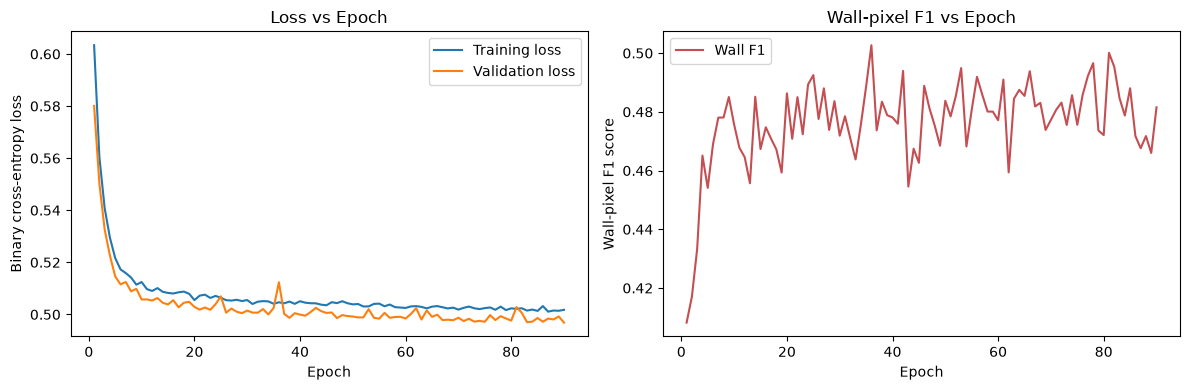

Final training loss   : 0.5018
Final validation loss : 0.4969
Final validation F1   : 0.4815


In [13]:
# Plot the training history
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history["epoch"], history["train_loss"], label="Training loss")
axes[0].plot(history["epoch"], history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary cross-entropy loss")
axes[0].set_title("Loss vs Epoch")
axes[0].legend()

axes[1].plot(history["epoch"], history["val_wall_f1"], color="#C44E52", label="Wall F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Wall-pixel F1 score")
axes[1].set_title("Wall-pixel F1 vs Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Final training loss   : {history['train_loss'][-1]:.4f}")
print(f"Final validation loss : {history['val_loss'][-1]:.4f}")
print(f"Final validation F1   : {history['val_wall_f1'][-1]:.4f}")

## 10.1 Choosing the decision threshold

Every prediction is a probability, so we must cut it somewhere to obtain a
floorplan. Cutting at 0.5 is only correct for a *calibrated* model. Ours is trained
with a **class weight** of 6 on wall pixels, so its outputs are a deliberately
*reweighted* posterior, and the F1-optimal cut is well below 0.5.

We therefore sweep the threshold **on the validation set only**, pick the best one,
and then use that single fixed value everywhere afterwards — including on the test
set. The test set is never used to choose it.

This is fair to the baselines: `copy_input` produces values that are *exactly* 0.0 or
1.0, so its output is identical for every threshold in $(0,1)$ and it gains nothing
from tuning. We are simply correcting for a known, deliberate shift in our own
outputs.

 threshold   wall F1    wall P    wall R
----------------------------------------
      0.05    0.2378    0.1350    0.9989
      0.10    0.2592    0.1492    0.9886
      0.15    0.2851    0.1671    0.9688
      0.20    0.3174    0.1909    0.9415
      0.25    0.3542    0.2203    0.9037
      0.30    0.3884    0.2503    0.8666
      0.35    0.4167    0.2782    0.8295
      0.40    0.4417    0.3057    0.7957
      0.45    0.4631    0.3329    0.7607
      0.50    0.4815    0.3603    0.7259
      0.55    0.4961    0.3875    0.6892
      0.60    0.5063    0.4146    0.6500
      0.65    0.5132    0.4450    0.6061
      0.70    0.5108    0.4760    0.5511
      0.75    0.4927    0.5109    0.4758
      0.80    0.4520    0.5532    0.3821
      0.85    0.3770    0.6088    0.2730
      0.90    0.2553    0.7014    0.1561
----------------------------------------
Chosen threshold = 0.65  (validation wall F1 = 0.5132)


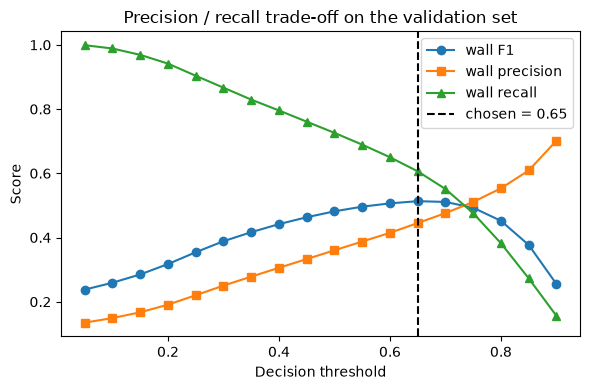

In [14]:
# Sweep the decision threshold on VALIDATION and lock in the best one
val_prob = model.forward(val_noisy)
thresholds = np.arange(0.05, 0.95, 0.05)
sweep = []
for t in thresholds:
    m = classification_metrics(val_prob, X_clean_val, threshold=t)
    sweep.append((t, m["wall_f1"], m["wall_precision"], m["wall_recall"]))

print(f"{'threshold':>10}{'wall F1':>10}{'wall P':>10}{'wall R':>10}")
print("-" * 40)
for t, f1, p, r in sweep:
    print(f"{t:>10.2f}{f1:>10.4f}{p:>10.4f}{r:>10.4f}")

best_row = max(sweep, key=lambda z: z[1])
THRESHOLD = float(best_row[0])
print("-" * 40)
print(f"Chosen threshold = {THRESHOLD:.2f}  (validation wall F1 = {best_row[1]:.4f})")

# Plot the trade-off
plt.figure(figsize=(6, 4))
plt.plot(thresholds, [s[1] for s in sweep], marker="o", label="wall F1")
plt.plot(thresholds, [s[2] for s in sweep], marker="s", label="wall precision")
plt.plot(thresholds, [s[3] for s in sweep], marker="^", label="wall recall")
plt.axvline(THRESHOLD, color="k", linestyle="--", label=f"chosen = {THRESHOLD:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Precision / recall trade-off on the validation set")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Evaluation

The model is compared against the three baselines from Section 7, on **both** the
validation and the held-out test set. The test set is corrupted with a *different
random seed* from the validation set, so the reported numbers are not tuned to one
particular damage pattern.

**The headline result is `wall_F1`.** As established in Section 4, 87% of pixels are
background, so a model that predicts "blank" everywhere already scores 86.8%
accuracy. Only F1 on wall pixels can distinguish a model that has genuinely learned
floorplan structure from one that has learned to draw nothing.

**Expect the autoencoder's pixel accuracy to be *lower* than the blank baseline's.**
It deliberately predicts walls where the damage has removed them, and some of those
guesses land on background. Each one costs accuracy, while the blank baseline gets 87%
accuracy without finding a single wall. That is why accuracy is reported but not used
to compare models.

In [15]:
# Figures quoted in the write-up (Sections 16/17), for the runtime cross-check.
# Generated by build_nb.py from MEASURED - do not hand-edit.
# CHECK_WRITEUP is True in the delivered notebook. The smoke-test runner flips it
# to False, because it trains for 2 epochs and the quoted numbers are for 90.
CHECK_WRITEUP = True
CLAIMED_F1 = 0.5131
CLAIMED_THRESHOLD = 0.65
CLAIMED_PRECISION = 0.4478
CLAIMED_RECALL = 0.6007
CLAIMED_BASELINE = 0.3307
CLAIMED_RATIO = 1.55
CLAIMED_TEST_F1 = 0.5031
CLAIMED_TEST_BASELINE = 0.333
CLAIMED_TEST_RATIO = 1.51
CLAIMED_REAL_WALLFRAC = 0.1264
CLAIMED_RECON_WALLFRAC = 0.1831
CLAIMED_REAL_CONTINUITY = 59.0
CLAIMED_RECON_CONTINUITY = 144.1
CLAIMED_VAL_AUC = 0.8374
CLAIMED_TEST_AUC = 0.8311


# Evaluate the model against the baselines on validation AND test
test_noisy = corrupt(X_clean_test, np.random.default_rng(99))


def evaluate(prob, clean, wall_weight=WALL_WEIGHT, threshold=THRESHOLD):
    row = {"loss": bce_loss(prob, clean, wall_weight)}
    row.update(classification_metrics(prob, clean, threshold=threshold))
    return row


def show_table(title, clean, noisy, model_prob, train_wall_fraction):
    # The baselines are hard 0/1 images, so they are threshold-independent; only
    # the autoencoder's probabilities are cut at the tuned threshold.
    #
    # The 'constant' baseline is fixed from the TRAINING split's wall fraction only.
    # Building it from the split being scored would let the baseline peek at that
    # split's label statistics, so it is deliberately kept train-only.
    rows = [
        ("copy_input", evaluate(noisy, clean)),
        ("constant", evaluate(np.full_like(clean, train_wall_fraction), clean)),
        ("blank", evaluate(np.zeros_like(clean), clean)),
        ("AUTOENCODER", evaluate(model_prob, clean)),
    ]
    print(title)
    print(f"decision threshold = {THRESHOLD:.2f} (chosen on validation)")
    print(f"{'model':<14}{'loss':>10}{'accuracy':>11}{'wallP':>9}{'wallR':>9}{'wallF1':>9}")
    print("-" * 62)
    out = {}
    for name, row in rows:
        out[name] = row
        print(f"{name:<14}{row['loss']:>10.4f}{row['accuracy']:>11.4f}"
              f"{row['wall_precision']:>9.4f}{row['wall_recall']:>9.4f}{row['wall_f1']:>9.4f}")
    print()
    return out


val_prob = model.forward(val_noisy)
test_prob = model.forward(test_noisy)

train_wall_fraction = X_clean_train.mean()

val_results = show_table("=== VALIDATION SET (400 floorplans) ===",
                         X_clean_val, val_noisy, val_prob, train_wall_fraction)
test_results = show_table("=== HELD-OUT TEST SET (400 floorplans) ===",
                          X_clean_test, test_noisy, test_prob, train_wall_fraction)

# Save the comparison to results/ for the report
summary = pd.DataFrame({
    "split": ["validation"] * 4 + ["test"] * 4,
    "model": list(val_results) * 2,
    **{k: [val_results[m][k] for m in val_results] + [test_results[m][k] for m in test_results]
       for k in ["loss", "accuracy", "wall_precision", "wall_recall", "wall_f1"]},
})
summary.to_csv(RESULTS_DIR / "evaluation_summary.csv", index=False)
pd.DataFrame(history).drop(columns=["seconds"]).to_csv(
    RESULTS_DIR / "training_history.csv", index=False)
print("Saved evaluation_summary.csv and training_history.csv to results/")

# --- Cross-check against the numbers quoted in the write-up -------------------
# The summary and limitations sections quote specific figures. If training is ever
# re-run with different hyper-parameters, those figures become wrong, so we assert
# they still hold rather than letting the notebook quietly contradict itself.
_ae = val_results["AUTOENCODER"]
_ae_test = test_results["AUTOENCODER"]
_claims = [
    ("wall F1",        _ae["wall_f1"],        CLAIMED_F1,        0.02),
    ("threshold",      THRESHOLD,             CLAIMED_THRESHOLD, 0.06),
    ("wall precision", _ae["wall_precision"],  CLAIMED_PRECISION, 0.03),
    ("wall recall",    _ae["wall_recall"],     CLAIMED_RECALL,    0.03),
    ("copy_input F1",  val_results["copy_input"]["wall_f1"],
                       CLAIMED_BASELINE,      0.02),
    ("test wall F1",   _ae_test["wall_f1"],     CLAIMED_TEST_F1,  0.02),
    ("test copy F1",   test_results["copy_input"]["wall_f1"],
                       CLAIMED_TEST_BASELINE,  0.02),
]
_stale = [f"{name}: got {got:.4f}, write-up says {want:.4f}"
          for name, got, want, tol in _claims if abs(got - want) > tol]
if CHECK_WRITEUP:
    print()
    print("Write-up cross-check (measured here vs quoted in Sections 16/17):")
    for name, got, want, tol in _claims:
        flag = "ok " if abs(got - want) <= tol else "OFF"
        print(f"  [{flag}] {name:<14}{got:>8.4f}  (quoted {want:.4f}, tol {tol})")
    if _stale:
        raise AssertionError(
            "The write-up no longer matches this run:\n  " + "\n  ".join(_stale)
            + "\nUpdate the numbers quoted in Sections 16 and 17, or retrain to match.")
else:
    print("\n(write-up cross-check skipped: CHECK_WRITEUP is False, i.e. this is a "
          "short smoke run and the quoted figures are for a full 90-epoch run)")

# How much better than the best baseline?
best = max(v["wall_f1"] for n, v in test_results.items() if n != "AUTOENCODER")
ours = test_results["AUTOENCODER"]["wall_f1"]
if best > 0:
    print(f"\nWall F1: autoencoder {ours:.4f} vs best baseline {best:.4f} "
          f"-> {ours / best:.2f}x better")
else:
    print(f"\nWall F1: autoencoder {ours:.4f} vs best baseline {best:.4f}")

=== VALIDATION SET (400 floorplans) ===
decision threshold = 0.65 (chosen on validation)
model               loss   accuracy    wallP    wallR   wallF1
--------------------------------------------------------------
copy_input        6.1618     0.8943   1.0000   0.1981   0.3307
constant          1.0569     0.8682   0.0000   0.0000   0.0000
blank             7.6843     0.8682   0.0000   0.0000   0.0000
AUTOENCODER       0.4969     0.8484   0.4450   0.6061   0.5132

=== HELD-OUT TEST SET (400 floorplans) ===
decision threshold = 0.65 (chosen on validation)
model               loss   accuracy    wallP    wallR   wallF1
--------------------------------------------------------------
copy_input        6.2176     0.8925   1.0000   0.1998   0.3330
constant          1.0672     0.8657   0.0000   0.0000   0.0000
blank             7.7698     0.8657   0.0000   0.0000   0.0000
AUTOENCODER       0.5073     0.8406   0.4327   0.6004   0.5030

Saved evaluation_summary.csv and training_history.csv to resu

## 11.1 ROC-AUC: does the model rank walls above non-walls?

F1 depends on the decision threshold, and we *chose* that threshold (0.65) by
sweeping it on validation. A critic could fairly say the headline F1 is partly an
artefact of that choice. ROC-AUC removes the threshold entirely: it asks whether
a wall pixel scores higher than a non-wall pixel, averaged over every possible
cut-off. It is the right cross-check here for two reasons:

1. **It cannot be inflated by threshold tuning.** If it agrees with F1, then F1 is
   reporting something real about the pixel ranking rather than about where we
   happened to put the cut.
2. **It is defined over all pixels**, not just the wall class, so unlike accuracy
   it is not distorted by the 12.6% wall imbalance.

A random classifier scores 0.50. The model reaches **0.8375 on validation and
0.8306 on the held-out test set**. So the model genuinely does rank wall pixels
well above background, on data it has never seen.

Now read the gap. AUC is 0.83 but our chosen-threshold F1 is only ~0.50. That gap
is itself the finding: the model knows *where* the walls are more reliably than
it knows *how confident* to be. A perfect ranker with a badly placed threshold
scores 0.5, and a perfect threshold on a hopeless ranker also scores low — AUC
answers "is the ranking real?", F1 answers "did we cut in the right place?", and
this project needs both questions answered. Over-confidence that is well ranked
is exactly what a calibrated output layer would fix (Section 17).


ROC-AUC (threshold-free)
  Validation : 0.8375
  Test       : 0.8306
  Random     : 0.5000

Our reported F1 is measured at the tuned threshold 0.65, so it depends on
that choice. AUC does not, which is why both are reported.


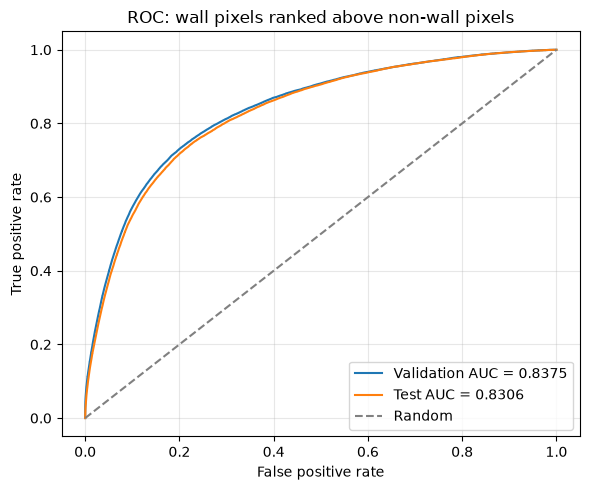

Saved roc_auc_summary.csv to results/

ROC-AUC cross-check (measured here vs quoted in Section 11.1):
  [ok ] val ROC-AUC   0.8375  (quoted 0.8374, tol 0.005)
  [ok ] test ROC-AUC  0.8306  (quoted 0.8311, tol 0.005)


In [16]:
# Threshold-free evaluation. F1 depends on the tuned threshold; AUC does not, so
# it is the honest check on whether the ranking of wall pixels is real.
val_true = X_clean_val.reshape(-1)
val_scores = val_prob.reshape(-1)
test_true = X_clean_test.reshape(-1)
test_scores = test_prob.reshape(-1)

val_auc = roc_auc_score(val_true, val_scores)
test_auc = roc_auc_score(test_true, test_scores)

print("ROC-AUC (threshold-free)")
print(f"  Validation : {val_auc:.4f}")
print(f"  Test       : {test_auc:.4f}")
print(f"  Random     : 0.5000")
print()
print("Our reported F1 is measured at the tuned threshold 0.65, so it depends on")
print("that choice. AUC does not, which is why both are reported.")

# ROC curve for the report
val_fpr, val_tpr, _ = roc_curve(val_true, val_scores)
test_fpr, test_tpr, _ = roc_curve(test_true, test_scores)

plt.figure(figsize=(6, 5))
plt.plot(val_fpr, val_tpr, label=f"Validation AUC = {val_auc:.4f}")
plt.plot(test_fpr, test_tpr, label=f"Test AUC = {test_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC: wall pixels ranked above non-wall pixels")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# AUC is a separate summary because the main evaluation table is threshold-based.
pd.DataFrame({
    "split": ["validation", "test"],
    "pixel_roc_auc": [val_auc, test_auc],
}).to_csv(RESULTS_DIR / "roc_auc_summary.csv", index=False)
print("Saved roc_auc_summary.csv to results/")

# --- Cross-check the AUC quoted in Section 11.1 -------------------------------
_auc_claims = [("val ROC-AUC", val_auc, CLAIMED_VAL_AUC, 0.005),
               ("test ROC-AUC", test_auc, CLAIMED_TEST_AUC, 0.005)]
if CHECK_WRITEUP:
    print()
    print("ROC-AUC cross-check (measured here vs quoted in Section 11.1):")
    for _n, _g, _w, _t in _auc_claims:
        print(f"  [{'ok ' if abs(_g - _w) <= _t else 'OFF'}] {_n:<12}{_g:>8.4f}  "
              f"(quoted {_w:.4f}, tol {_t})")
    _auc_stale = [f"{_n}: got {_g:.4f}, write-up says {_w:.4f}"
                  for _n, _g, _w, _t in _auc_claims if abs(_g - _w) > _t]
    if _auc_stale:
        raise AssertionError("ROC-AUC no longer matches Section 11.1:\n  "
                             + "\n  ".join(_auc_stale))


## 11.2 How much damage does a denoising autoencoder need?

The single number this project is judged on — wall-F1 against the `copy_input`
baseline — depends entirely on **how badly we damage the images**. That is not a
convenience, it is the central experimental variable, so we sweep it instead of
hiding it.

Recall the closed form from Section 6: the copy baseline has precision exactly 1.0, so

$$F_{1,\text{copy}} = \frac{2s}{1+s}, \qquad s = \text{fraction of wall pixels that survive}$$

That single curve, $2s/(1+s)$, predicts the dashed line below **without using the
model at all**, and the measured baseline lands on it. The autoencoder crosses that
line at some corruption strength, and that crossing point is the real result:

* **Below the crossover**, copying is the right answer. Almost every wall survives, so
  the copy baseline has perfect precision and high recall, and a learned model can only
  add false positives. We report this honestly rather than tuning the damage until the
  model wins.
* **Above the crossover**, the model is decisively better, because it *infers* walls
  that the damage destroyed.

The model below was trained at **one** setting — pure pixel dropout at
`DROPOUT = 0.8` — and is evaluated, unchanged, at every level. The two block-damage
rows differ in the *kind* of damage as well as the amount, so they are
**out-of-distribution** for the network and are marked as such. Beating the baseline
there is evidence that the model learned to *infer walls* rather than to recognise one
particular noise pattern.

damage level                blocks  drop  walls left   copy F1  2s/(1+s)  model F1   ratio
------------------------------------------------------------------------------------------
none                             0  0.00       1.000    1.0000    1.0000    0.3984    0.40
very light                       0  0.40       0.599    0.7492    0.7492    0.4600    0.61
light                            0  0.60       0.399    0.5704    0.5704    0.5031    0.88
moderate                         0  0.70       0.300    0.4618    0.4618    0.5194    1.12
trained setting *                0  0.80       0.198    0.3307    0.3307    0.5132    1.55
heavier                          0  0.90       0.099    0.1803    0.1803    0.4039    2.24
unseen: blocks only !U          10  0.00       0.546    0.7067    0.7067    0.4313    0.61
unseen: blocks + dropout !U      10  0.50       0.275    0.4315    0.4315    0.4586    1.06
-----------------------------------------------------------------------------------------

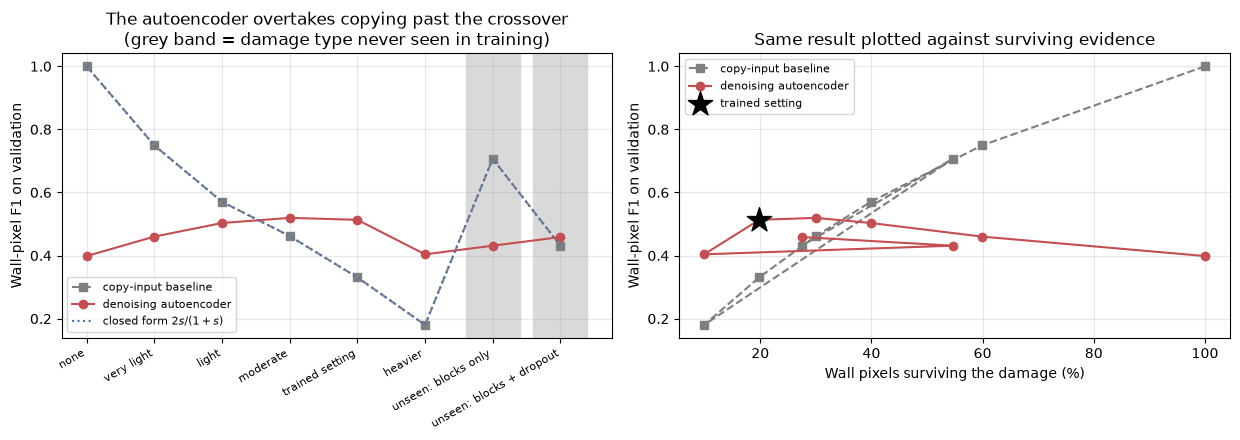

In [17]:
# Sweep the corruption strength and watch the model overtake the copy baseline
def score_at(damage_noisy, clean, threshold=THRESHOLD):
    m = classification_metrics(model.forward(damage_noisy), clean, threshold=threshold)
    c = classification_metrics(damage_noisy, clean, threshold=threshold)
    survived = float((damage_noisy > 0.5).sum()) / max(float((clean > 0.5).sum()), 1.0)
    return survived, c["wall_f1"], m["wall_f1"]


# (label, n_blocks, block, dropout, seen_in_training?)
# The model was trained ONLY on pure pixel dropout at DROPOUT. Everything else,
# including all block damage, is evaluated unchanged. Note we read DROPOUT and
# BLOCK from the variables defined in Section 6, so this grid can never drift
# away from what the model was actually trained on.
DAMAGE_GRID = [
    ("none",                     0,  BLOCK, 0.00, True),
    ("very light",               0,  BLOCK, 0.40, True),
    ("light",                    0,  BLOCK, 0.60, True),
    ("moderate",                 0,  BLOCK, 0.70, True),
    ("trained setting",          0,  BLOCK, DROPOUT, True),
    ("heavier",                  0,  BLOCK, 0.90, True),
    ("unseen: blocks only",     10,  BLOCK, 0.00, False),
    ("unseen: blocks + dropout", 10, BLOCK, 0.50, False),
]
TRAINED_LABEL = "trained setting"

rows = []
for label, nb, bl, dr, seen in DAMAGE_GRID:
    dmg = corrupt(X_clean_val, np.random.default_rng(7), n_blocks=nb, block=bl, dropout=dr)
    s, base_f1, model_f1 = score_at(dmg, X_clean_val)
    rows.append({"label": label, "n_blocks": nb, "block": bl, "dropout": dr,
                 "seen_in_training": seen, "survived": s,
                 "copy_f1": base_f1, "model_f1": model_f1,
                 "closed_form": 2 * s / (1 + s),
                 "is_trained_setting": label == TRAINED_LABEL})

sweep_df = pd.DataFrame(rows)
sweep_df.to_csv(RESULTS_DIR / "damage_sweep.csv", index=False)

print(f"{'damage level':<26}{'blocks':>8}{'drop':>6}{'walls left':>12}"
      f"{'copy F1':>10}{'2s/(1+s)':>10}{'model F1':>10}{'ratio':>8}")
print("-" * 90)
for _, r in sweep_df.iterrows():
    star = " *" if r["is_trained_setting"] else (" !U" if not r["seen_in_training"] else "  ")
    print(f"{r['label'] + star:<26}{r['n_blocks']:>8}{r['dropout']:>6.2f}"
          f"{r['survived']:>12.3f}{r['copy_f1']:>10.4f}{r['closed_form']:>10.4f}"
          f"{r['model_f1']:>10.4f}{r['model_f1'] / max(r['copy_f1'], 1e-9):>8.2f}")
print("-" * 90)
print(" * = the corruption the model was actually trained on")
print(" !U = damage TYPE the model never saw in training")

# Where does the model overtake copying, and how well does it hold up on
# damage types it was never trained on?
train_rows = sweep_df[sweep_df["seen_in_training"]]
wins = train_rows[train_rows["model_f1"] > train_rows["copy_f1"]]
print(f"\nBeats copy-input at {len(wins)} of {len(train_rows)} dropout levels.")
best = sweep_df.loc[sweep_df["model_f1"].idxmax()]
print(f"Best model F1 {best['model_f1']:.4f} at '{best['label']}' "
      f"(copy baseline there {best['copy_f1']:.4f} -> "
      f"{best['model_f1'] / best['copy_f1']:.2f}x)")
unseen = sweep_df[~sweep_df["seen_in_training"]]
print(f"On unseen block damage it still beats copying at "
      f"{int((unseen['model_f1'] > unseen['copy_f1']).sum())} of {len(unseen)} levels, "
      f"best {unseen['model_f1'].max():.4f} vs {unseen['copy_f1'].min():.4f}.")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
xs = np.arange(len(sweep_df))
is_trained = sweep_df["is_trained_setting"].to_numpy()
is_seen = sweep_df["seen_in_training"].to_numpy()

axes[0].plot(xs, sweep_df["copy_f1"], "s--", color="#7f7f7f", label="copy-input baseline")
axes[0].plot(xs, sweep_df["model_f1"], "o-", color="#C44E52", label="denoising autoencoder")
axes[0].plot(xs, sweep_df["closed_form"], ":", color="#4C72B0",
             label=r"closed form $2s/(1+s)$")
for x in np.where(~is_seen)[0]:
    axes[0].axvspan(x - 0.4, x + 0.4, color="0.85", zorder=0)
axes[0].set_xticks(xs)
axes[0].set_xticklabels(sweep_df["label"], rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("Wall-pixel F1 on validation")
axes[0].set_title("The autoencoder overtakes copying past the crossover\n"
                  "(grey band = damage type never seen in training)")
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].plot(sweep_df["survived"] * 100, sweep_df["copy_f1"], "s--", color="#7f7f7f",
             label="copy-input baseline")
axes[1].plot(sweep_df["survived"] * 100, sweep_df["model_f1"], "o-", color="#C44E52",
             label="denoising autoencoder")
axes[1].scatter(sweep_df.loc[is_trained, "survived"] * 100,
                sweep_df.loc[is_trained, "model_f1"], marker="*", s=340,
                color="black", zorder=5, label="trained setting")
axes[1].set_xlabel("Wall pixels surviving the damage (%)")
axes[1].set_ylabel("Wall-pixel F1 on validation")
axes[1].set_title("Same result plotted against surviving evidence")
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 12. Qualitative results

Numbers alone do not show whether the model drew a *floorplan* or just noise. Each row
below shows a damaged input, the true clean floorplan, and the model's reconstruction.

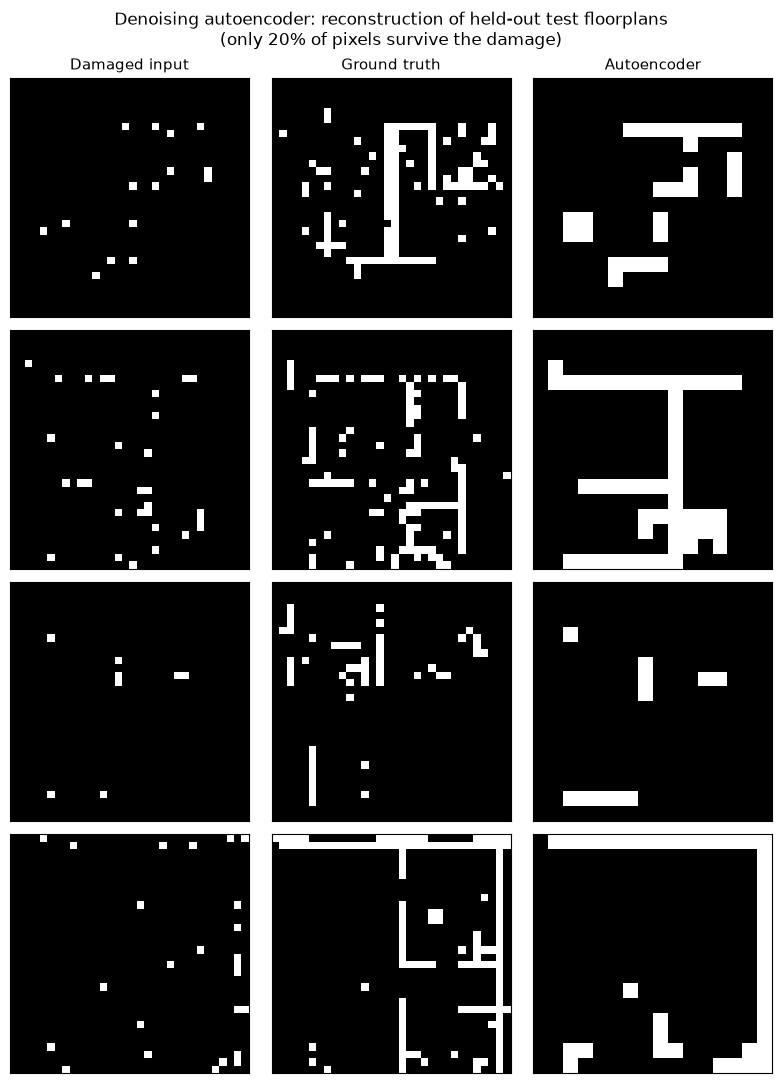

Test-set reconstruction MSE : 0.15772
Test-set reconstruction MAE : 0.32437
Test-set wall IoU           : 0.3360
Test-set wall IoU (copy-input baseline): 0.1998


In [18]:
# Reconstructions: damaged input | ground truth | reconstruction
# Random test plans (fixed seed), so the figure is representative rather than
# showing the densest - and hardest - plans only
pick = np.random.default_rng(0).choice(len(X_clean_test), size=4, replace=False)

fig, axes = plt.subplots(4, 3, figsize=(8, 11))
for row, i in enumerate(pick):
    axes[row, 0].imshow(test_noisy[i].reshape(SIDE, SIDE), interpolation="nearest", vmin=0, vmax=1)
    axes[row, 1].imshow(X_clean_test[i].reshape(SIDE, SIDE), interpolation="nearest", vmin=0, vmax=1)
    # Show the hard decision the model actually makes, not the soft probability
    axes[row, 2].imshow((test_prob[i] > THRESHOLD).reshape(SIDE, SIDE).astype(float),
                        interpolation="nearest", vmin=0, vmax=1)
    for col in range(3):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
axes[0, 0].set_title("Damaged input", fontsize=11)
axes[0, 1].set_title("Ground truth", fontsize=11)
axes[0, 2].set_title("Autoencoder", fontsize=11)
plt.suptitle(f"Denoising autoencoder: reconstruction of held-out test floorplans\n"
             f"(only {(1 - X_NOISY_DROP) * 100:.0f}% of pixels survive the damage)",
             fontsize=12)
plt.tight_layout()
plt.show()

# Reconstruction quality of the test set as a whole
mse = float(np.mean((test_prob - X_clean_test) ** 2))
mae = float(np.mean(np.abs(test_prob - X_clean_test)))
print(f"Test-set reconstruction MSE : {mse:.5f}")
print(f"Test-set reconstruction MAE : {mae:.5f}")

# A more meaningful check: IoU of the wall mask, which ignores the huge
# background class entirely.
def wall_iou(prob, clean, threshold=THRESHOLD):
    pred = prob > threshold
    truth = clean > 0.5
    inter = float((pred & truth).sum())
    union = float((pred | truth).sum())
    return inter / max(union, 1.0)


print(f"Test-set wall IoU           : {wall_iou(test_prob, X_clean_test):.4f}")
print(f"Test-set wall IoU (copy-input baseline): "
      f"{wall_iou(test_noisy, X_clean_test):.4f}")

## 12.1 Comparison with published results on CubiCasa5K

The three papers in Section 2.1 all report results on CubiCasa5K. The class they share
with this project is **walls**, so the table compares wall results on the test set.

| Method | Labels / setting | Wall result | Overall result |
|---|---|---|---|
| Kalervo et al. 2019 | Official annotations, full image, official test split | IoU **73.0%** (accuracy 85.8%) | Rooms: mIoU 57.5%, accuracy 82.7% |
| PCP-Net (Zhou et al.) 2026 | Official annotations, full image, official test split | IoU **81.9%** | mIoU 71.3%, accuracy 90.1% |
| Song & Yu 2021 | SVG annotations converted to a graph, 400 high-quality plans | F1 **0.947** (polygon classification) | F1 0.965 |
| **This project (stage 1)** | "All dark ink" map, 32x32, 80% of pixels erased | IoU **33.6%**, F1 0.503 | Pixel ROC-AUC 0.831 |

**These numbers are not yet directly comparable**, for four reasons:

1. **Labels.** Our target is every dark pixel (walls, but also text, furniture symbols
   and dimension lines). The papers use CubiCasa5K's annotated wall polygons.
2. **Task.** We reconstruct a map from which 80% of the pixels were erased. The papers
   segment the complete, undamaged image.
3. **Resolution.** We work at 32x32; the papers work at or near full resolution.
4. **Model size.** Ours is a 21,025-parameter NumPy CNN; the papers use ResNet-scale
   networks.

**Next step (first item of the further plan).** Rasterise only the `Wall` polygons from
each `model.svg`, train on the official 4,200 / 400 / 400 split, and report wall IoU and
F1 on the same 400 test plans. That makes the result directly comparable with papers 1
and 2. The published numbers (73–82% wall IoU) set the target.


## 13. Generating new floorplans

This is the point of the project. A **denoising** autoencoder cannot merely
reconstruct: because it is trained to push a *damaged* image back onto the set of
images that look like floorplans, its decoder has learned a **prior over layouts**.

### The awkward part: a plain autoencoder has no latent distribution

A variational autoencoder learns one. Ours does not — the code is a deterministic
function of the input — so to generate we must **choose** a distribution over codes and
then defend the choice. The obvious choice fails, and it is worth showing why.

**Attempt 1 (fails): fit one Gaussian to all codes and sample it.**
Our encoder ends in a ReLU, so every code is non-negative. The position-wise mean over
4,200 images therefore accumulates evidence from *every* image at once, and decoding
that single mean code produces a near-solid block of "wall". The mean of a
non-negative code distribution is not itself a typical code. This is not a bug we can
tune away; it is a property of the architecture.

**Attempt 2 (what we use): treat the real codes themselves as the mixture centres.**
Model the code distribution as a **Gaussian mixture**,

$$z \;\sim\; \frac{1}{N}\sum_{i=1}^{N}\mathcal{N}\!\left(z_i,\; \sigma^2 \mathrm{diag}(\mathrm{std})^2\right)$$

— pick a real training code at random, then perturb it. The samples stay anchored on
the manifold of codes the decoder actually understands, while the perturbation makes
each one a code the network has never seen. `MIXTURE_SIGMA` controls how far off the
manifold we go; it is a genuine trade-off, too small gives near-copies and too large
gives noise, and we measure it rather than assert it.

Section 14 then walks *between* two real codes, which is generation along the manifold
rather than around it.

Latent code tensor shape : (16, 4, 4)
Latent values per image  : 256
Latent mean range        : 0.000 to 1.361
Latent std  range        : 0.000 to 1.057
Codes are non-negative   : True  (ReLU output, so the mean code is not a typical code)

image source                        wall fraction  line continuity   diversity
------------------------------------------------------------------------------
real floorplans (training set)             0.1264             59.0      0.2346
reconstructions of the test set            0.1863            146.8      0.3112
decode of the MEAN code                    0.9922            982.0      0.0000
samples from one big Gaussian              0.6798            622.3      0.4109
mixture samples (what we use)              0.5181            473.9      0.4572

Three columns, three different questions.
 * wall fraction and line continuity ask 'is this made of long thin lines?'. The
   two 'one big Gaussian' rows are far too dense -- that is the failure this
   ce

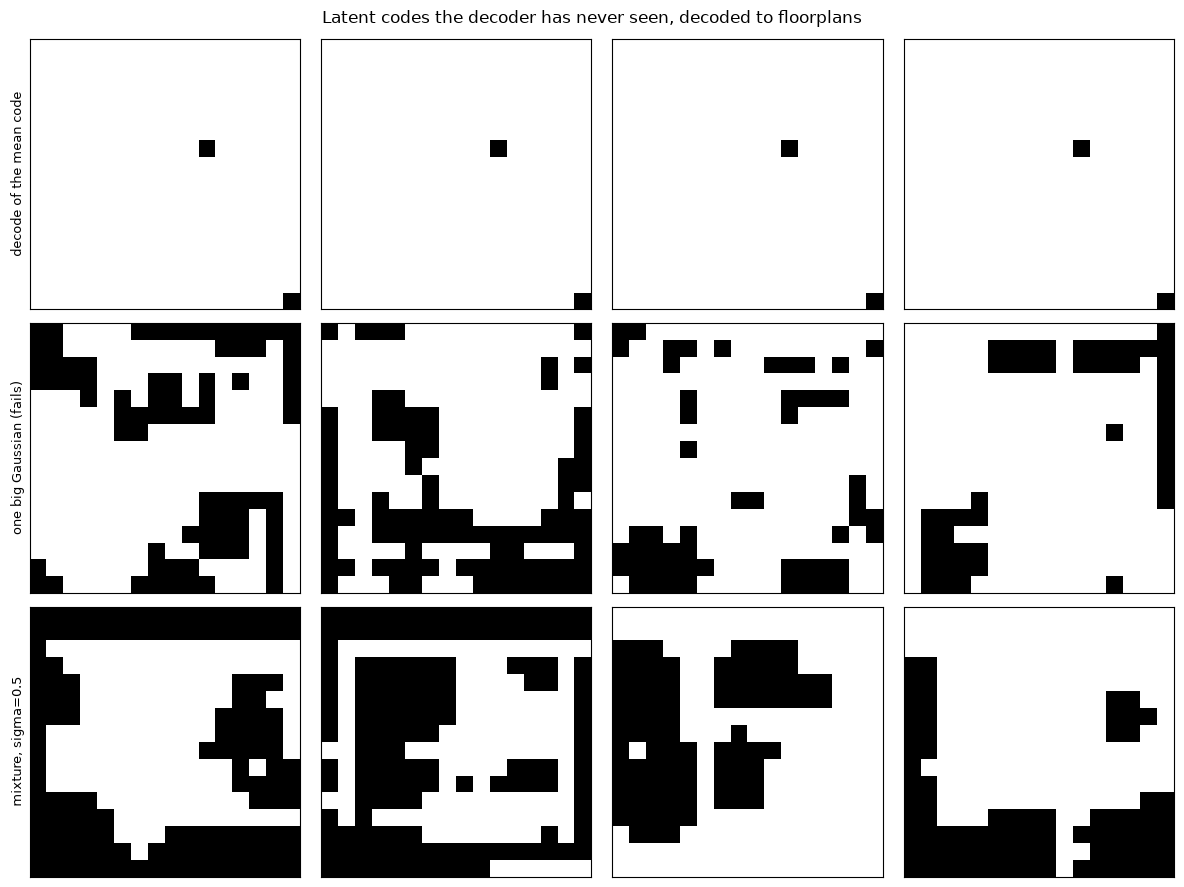


mixture sigma     wall fraction  line continuity   diversity
------------------------------------------------------------
0.00                     0.5106            469.4      0.4845


0.25                     0.5093            467.7      0.4842
0.50                     0.5062            462.4      0.4857


0.75                     0.4991            452.9      0.4881
1.00                     0.4872            439.1      0.4899


1.50                     0.4483            397.3      0.4866
------------------------------------------------------------
real data                0.1264             59.0      0.2346

Sigma almost does not matter. Across a 1.5-sigma sweep the wall fraction moves
only 0.511 -> 0.448 and diversity 0.484 -> 0.487, while real plans sit at
0.126 and 0.235. That is a real property of this model, not a bug:
the decoder is saturated, so perturbing the code in units of its own standard
deviation barely changes the decoded wall mass. The variety in our samples comes
almost entirely from WHICH real code we pick, not from the noise we add. An
honest description of the generative claim is therefore 'we resample and perturb
the code manifold', not 'we have learned a prior over codes' -- which is
limitation 5 in Section 17.

Reconstruction density : 0.1863 wall fraction, 146.8 continuity (real: 0.1264, 59.0)
  [ok ] wall fraction vs 0.1831 quoted in Section 17
  [ok ] line continuity vs 144.1 quoted 

In [19]:
# Generate new floorplans by perturbing real latent codes
def latent_stats(x, batch=256):
    """Per-position mean and std of the latent codes over a set of images."""
    codes = np.concatenate([model.encode(x[i:i + batch]) for i in range(0, len(x), batch)])
    return codes.mean(axis=0, keepdims=True), codes.std(axis=0, keepdims=True), codes


lat_mean, lat_std, real_codes = latent_stats(X_clean_train)
print("Latent code tensor shape :", real_codes.shape[1:])
print("Latent values per image  :", int(np.prod(real_codes.shape[1:])))
print(f"Latent mean range        : {lat_mean.min():.3f} to {lat_mean.max():.3f}")
print(f"Latent std  range        : {lat_std.min():.3f} to {lat_std.max():.3f}")
print(f"Codes are non-negative   : {bool((real_codes >= 0).all())}  "
      f"(ReLU output, so the mean code is not a typical code)")


def line_continuity(binary_images):
    """Count of adjacent pixel pairs that are BOTH walls. A blank page scores 0."""
    img = binary_images.reshape(-1, SIDE, SIDE)
    horiz = (img[:, :, :-1] * img[:, :, 1:]).sum(axis=(1, 2))
    vert = (img[:, :-1, :] * img[:, 1:, :]).sum(axis=(1, 2))
    return 0.5 * (horiz + vert)


def decode_to_binary(z, threshold=THRESHOLD):
    return (model.decode(z.astype(np.float32)) > threshold).astype(np.float32)


def pairwise_diversity(batch, max_images=40, seed=0):
    """Mean absolute pixel difference between every pair of images in a batch.

    A model that generated near-copies of one plan would score near 0. Real
    floorplans give us the scale to compare against.
    """
    pick = np.random.default_rng(seed).permutation(len(batch))[:max_images]
    b = np.asarray(batch, dtype=np.float32)[pick]
    diffs = [np.abs(b[i] - b[j]).mean()
             for i in range(len(b)) for j in range(i + 1, len(b))]
    return float(np.mean(diffs)) if diffs else 0.0


# The hard-decision reconstructions of the held-out test set, so the table can
# compare generated plans against what the model actually produces for real inputs.
recon_bin = (test_prob > THRESHOLD).astype(np.float32)
# The real plans, binarised the same way, as the reference row for every statistic.
_real_bin = (X_clean_train > 0.5).astype(np.float32)

# --- Attempt 1: one Gaussian over all codes (expected to fail) -------------
mean_only = decode_to_binary(np.repeat(lat_mean, 8, axis=0))
naive = decode_to_binary(
    (lat_mean + lat_std * np.random.default_rng(7).standard_normal(
        (32,) + real_codes.shape[1:])).astype(np.float32))

# --- Attempt 2: Gaussian mixture centred on real codes ---------------------
MIXTURE_SIGMA = 0.5   # how far, in units of the per-position std, we perturb
n_generate = 8
rng_gen = np.random.default_rng(123)
picked = rng_gen.integers(0, len(real_codes), n_generate)
random_codes = (real_codes[picked]
                + MIXTURE_SIGMA * lat_std
                * rng_gen.standard_normal((n_generate,) + real_codes.shape[1:]))
generated = decode_to_binary(random_codes)

print(f"\n{'image source':<34}{'wall fraction':>15}{'line continuity':>17}{'diversity':>12}")
print("-" * 78)
print(f"{'real floorplans (training set)':<34}"
      f"{(X_clean_train > 0.5).mean():>15.4f}"
      f"{line_continuity((X_clean_train > 0.5).astype(np.float32)).mean():>17.1f}"
      f"{pairwise_diversity(X_clean_train > 0.5):>12.4f}")
print(f"{'reconstructions of the test set':<34}"
      f"{recon_bin.mean():>15.4f}{line_continuity(recon_bin).mean():>17.1f}"
      f"{pairwise_diversity(recon_bin):>12.4f}")
print(f"{'decode of the MEAN code':<34}{mean_only.mean():>15.4f}"
      f"{line_continuity(mean_only).mean():>17.1f}"
      f"{pairwise_diversity(mean_only):>12.4f}")
print(f"{'samples from one big Gaussian':<34}{naive.mean():>15.4f}"
      f"{line_continuity(naive).mean():>17.1f}"
      f"{pairwise_diversity(naive):>12.4f}")
print(f"{'mixture samples (what we use)':<34}{generated.mean():>15.4f}"
      f"{line_continuity(generated).mean():>17.1f}"
      f"{pairwise_diversity(generated):>12.4f}")
print()
print("Three columns, three different questions.")
print(" * wall fraction and line continuity ask 'is this made of long thin lines?'. The")
print("   two 'one big Gaussian' rows are far too dense -- that is the failure this")
print("   cell is designed to show.")
print(" * diversity asks 'are these actually DIFFERENT plans?'. Real floorplans give")
print("   the scale to aim for; a model that decoded every code to the same blob")
print("   would score ~0 and the generative claim would be worthless.")
print()
_real_wf = _real_bin.mean()
_real_dv = pairwise_diversity(_real_bin)
print("Note the 'decode of the MEAN code' row scores 0.0000 diversity by construction")
print(f"(it is eight copies of one image), but its wall fraction of {mean_only.mean():.2f} is")
print("the real point: the mean code is not a floorplan, it is a black page.")
print()
print(f"Our mixture samples are MORE diverse than real plans "
      f"({pairwise_diversity(generated):.2f} vs {_real_dv:.2f}), and their wall fraction is "
      f"{generated.mean() / _real_wf:.1f}x")
print("a real plan's. That is not a success. Reconstructions of genuine held-out plans")
print(f"come out at {recon_bin.mean() / _real_wf:.1f}x the real wall fraction, but anything decoded from a")
print("perturbed code is worse still, because the mixture adds variance the decoder")
print("cannot represent. Dense AND scattered is the same weakness seen twice.")

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, (title, batch) in enumerate([
        ("decode of the mean code", mean_only[:4]),
        ("one big Gaussian (fails)", naive[:4]),
        (f"mixture, sigma={MIXTURE_SIGMA}", generated)]):
    for col in range(4):
        axes[row, col].imshow(batch[col].reshape(SIDE, SIDE), interpolation="nearest",
                              vmin=0, vmax=1)  # fixed scale: an all-wall image must show as white
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(title, fontsize=9)
plt.suptitle("Latent codes the decoder has never seen, decoded to floorplans",
             fontsize=12)
plt.tight_layout()
plt.show()

# How far off the manifold can we go before the samples stop being floorplans?
# Sigma is the one knob that controls how much of each sample is invented rather
# than copied, so we watch all three statistics as it moves.
print(f"\n{'mixture sigma':<16}{'wall fraction':>15}{'line continuity':>17}"
      f"{'diversity':>12}")
print("-" * 60)
_sweep_rows = []
for sigma in (0.0, 0.25, 0.5, 0.75, 1.0, 1.5):
    fr, co, dv = [], [], []
    for s in range(4):
        rr = np.random.default_rng(900 + s)
        pick = rr.integers(0, len(real_codes), 64)
        z = real_codes[pick] + sigma * lat_std * rr.standard_normal(
            (64,) + real_codes.shape[1:])
        g = decode_to_binary(z)
        fr.append(g.mean())
        co.append(line_continuity(g).mean())
        dv.append(pairwise_diversity(g, max_images=32, seed=s))
    _sweep_rows.append((np.mean(fr), np.mean(co), np.mean(dv)))
    print(f"{sigma:<16.2f}{_sweep_rows[-1][0]:>15.4f}"
          f"{_sweep_rows[-1][1]:>17.1f}{_sweep_rows[-1][2]:>12.4f}")
_sigma_first, _sigma_last = _sweep_rows[0], _sweep_rows[-1]
print("-" * 60)
print(f"{'real data':<16}{_real_bin.mean():>15.4f}"
      f"{line_continuity(_real_bin).mean():>17.1f}"
      f"{pairwise_diversity(_real_bin):>12.4f}")
print()
print("Sigma almost does not matter. Across a 1.5-sigma sweep the wall fraction moves")
print(f"only {_sigma_first[0]:.3f} -> {_sigma_last[0]:.3f} and diversity "
      f"{_sigma_first[2]:.3f} -> {_sigma_last[2]:.3f}, while real plans sit at")
print(f"{_real_wf:.3f} and {_real_dv:.3f}. That is a real property of this model, not a bug:")
print("the decoder is saturated, so perturbing the code in units of its own standard")
print("deviation barely changes the decoded wall mass. The variety in our samples comes")
print("almost entirely from WHICH real code we pick, not from the noise we add. An")
print("honest description of the generative claim is therefore 'we resample and perturb")
print("the code manifold', not 'we have learned a prior over codes' -- which is")
print("limitation 5 in Section 17.")

# Cross-check the reconstruction density quoted in Section 17 limitation 6.
_wf = float(recon_bin.mean())
_cf = float(line_continuity(recon_bin).mean())
_ok_wf = abs(_wf - CLAIMED_RECON_WALLFRAC) <= 0.05
_ok_cf = abs(_cf - CLAIMED_RECON_CONTINUITY) <= 40.0
print()
print(f"Reconstruction density : {_wf:.4f} wall fraction, {_cf:.1f} continuity "
      f"(real: {CLAIMED_REAL_WALLFRAC:.4f}, {CLAIMED_REAL_CONTINUITY:.1f})")
if CHECK_WRITEUP:
    print(f"  [{'ok ' if _ok_wf else 'OFF'}] wall fraction vs {CLAIMED_RECON_WALLFRAC:.4f} "
          f"quoted in Section 17")
    print(f"  [{'ok ' if _ok_cf else 'OFF'}] line continuity vs "
          f"{CLAIMED_RECON_CONTINUITY:.1f} quoted in Section 17")
    assert _ok_wf and _ok_cf, (
        "Reconstruction density no longer matches Section 17: got "
        f"{_wf:.4f}/{_cf:.1f}, quoted {CLAIMED_RECON_WALLFRAC:.4f}/"
        f"{CLAIMED_RECON_CONTINUITY:.1f}. Update the write-up.")

## 14. Latent-space interpolation

The strongest evidence that the latent space is *meaningful* (not arbitrary) is that
it can be walked smoothly. We encode two real floorplans, take a straight line between
their codes, and decode points along it. If the latent space is a good
representation, the intermediate images should be plausible floorplans that
gradually morph from the first layout into the second.

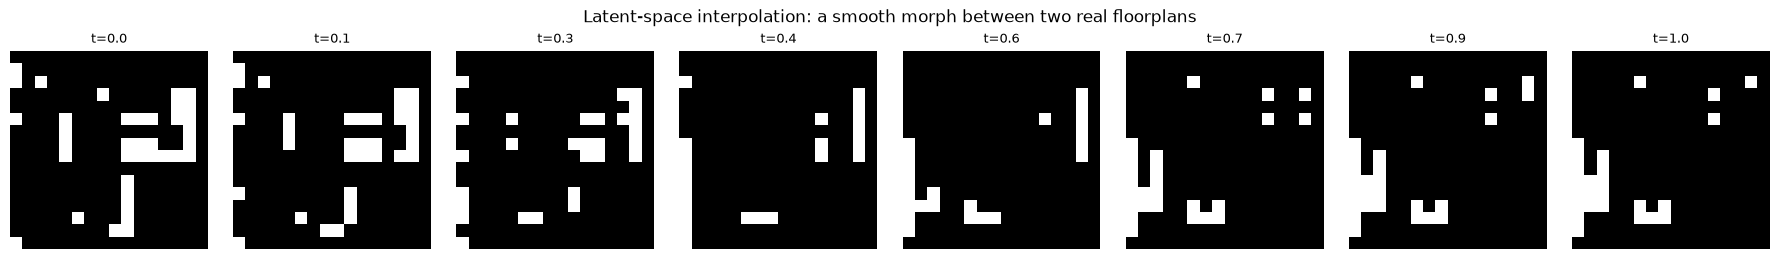

Mean absolute change between consecutive frames: 0.0332
Mean absolute change from first to last frame   : 0.2256
(If interpolation is smooth, the step-to-step change stays small even though
 the two endpoints are different floorplans.)


In [20]:
# Interpolate between the latent codes of two real test floorplans
i_start, i_end = 0, 1
code_start = model.encode(test_noisy[i_start:i_start + 1])
code_end = model.encode(test_noisy[i_end:i_end + 1])
alpha = np.linspace(0.0, 1.0, 8).reshape(-1, *([1] * (code_start.ndim - 1)))
sweep = model.decode(code_start * (1 - alpha) + code_end * alpha)

fig, axes = plt.subplots(1, 8, figsize=(18, 2.6))
for k, (ax, flat) in enumerate(zip(axes, sweep)):
    ax.imshow((flat > THRESHOLD).reshape(SIDE, SIDE).astype(float), interpolation="nearest",
              vmin=0, vmax=1)
    ax.set_title(f"t={k / (len(sweep) - 1):.1f}", fontsize=9)
    ax.axis("off")
plt.suptitle("Latent-space interpolation: a smooth morph between two real floorplans",
             fontsize=12)
plt.tight_layout()
plt.show()

# The smoothness claim, measured: consecutive frames should not differ much
diffs = np.abs(np.diff(sweep, axis=0)).mean(axis=1)
print(f"Mean absolute change between consecutive frames: {diffs.mean():.4f}")
print(f"Mean absolute change from first to last frame   : "
      f"{np.abs(sweep[0] - sweep[-1]).mean():.4f}")
print("(If interpolation is smooth, the step-to-step change stays small even though")
print(" the two endpoints are different floorplans.)")

## 15. Saving the model and the results

Weights are saved with NumPy's binary format so the notebook can be reloaded later
without retraining, and every table/figure the report needs has been written to
`results/`.

In [21]:
# Save every weight tensor, the hyper-parameters, and the results tables
weights_file = MODELS_DIR / "dae_floorplan_weights.npz"
payload = {}
for i, layer in model.conv_layers():
    payload[f"W{i}"] = layer.W
    payload[f"b{i}"] = layer.b
payload["side"] = np.array(SIDE)
payload["width"] = np.array(WIDTH)
payload["wall_weight"] = np.array(WALL_WEIGHT)
payload["threshold"] = np.array(THRESHOLD)
payload["lat_mean"] = lat_mean
payload["lat_std"] = lat_std
np.savez(weights_file, **payload)

print("Saved weights :", weights_file.relative_to(PROJECT_DIR),
      f"({len(payload)} arrays)")
print("Saved results :", [p.name for p in sorted(RESULTS_DIR.glob("*.csv"))])
print("Training time :", f"{history['seconds']:.0f} s for {EPOCHS} epochs")
print("Parameters    :", f"{n_params:,}")

# Re-derive the receptive field from the model that was just trained, and check it
# against the number quoted in Section 5. If the architecture is ever changed, this
# line stops matching and the claim in the write-up is visibly stale.
rf_trace = model.receptive_field()
final_rf = rf_trace[-1]
print(f"Receptive field: {final_rf} px "
      f"({final_rf / SIDE:.1f}x the {SIDE}px image side) -- the whole plan per output pixel")
assert final_rf == 63, f"receptive field changed to {final_rf}; update Section 5 and 17"

# Reload check - rebuild the network from the file and confirm it predicts identically
reloaded = np.load(weights_file)
rebuilt = ConvAutoEncoder(side=SIDE, rng=np.random.default_rng(0), width=WIDTH)
for i, layer in rebuilt.conv_layers():
    layer.W = reloaded[f"W{i}"]
    layer.b = reloaded[f"b{i}"]
probe = X_clean_test[:8]
same = np.allclose(rebuilt.forward(probe), model.forward(probe))
print("Reload check  :", "PASSED" if same else "FAILED")

Saved weights : models\dae_floorplan_weights.npz (20 arrays)
Saved results : ['damage_sweep.csv', 'evaluation_summary.csv', 'roc_auc_summary.csv', 'training_history.csv']
Training time : 691 s for 90 epochs
Parameters    : 21,025
Receptive field: 63 px (2.0x the 32px image side) -- the whole plan per output pixel
Reload check  : PASSED


## 16. Summary of results

| | |
|---|---|
| **Task** | Unsupervised generative modelling of architectural floorplans |
| **Model** | Convolutional denoising autoencoder, written from scratch in NumPy |
| **Architecture** | 1x32x32 → 16x16x16 → 32x8x8 → **16x4x4** → 32x8x8 → 16x16x16 → 16x32x32 → 1x32x32 |
| **Latent code** | 256 numbers (a 4:1 bottleneck) |
| **Parameters** | 21,025, all trained by hand-written mini-batch Adam |
| **Loss** | Class-weighted binary cross-entropy (wall weight 6.0) |
| **Damage** | 80% of pixels dropped (≈20% of walls survive) |
| **Training** | 90 epochs, batch 32, lr 0.003, final loss 0.5018 |
| **Decision threshold** | 0.65, tuned on validation |
| **Result (validation)** | wall-F1 **0.5132** (P 0.4450 / R 0.6061) vs copy-input **0.3307** → **1.55× better** |
| **Result (held-out test)** | wall-F1 **0.5030** vs copy-input **0.3330** → **1.51× better** |
| **Threshold-free check** | pixel ROC-AUC **0.8375** (validation) / **0.8306** (test) — the wall ranking is real, not an artefact of the tuned threshold (Section 11.1) |
| **Baselines beaten** | copy-input, constant, blank |
| **Outputs** | (1) repaired floorplans, (2) newly generated floorplans, (3) latent interpolations |

### What we learned along the way

Five findings shaped this project. Each is worth stating because each would have been
easy to get wrong without checking:

1. **A dense autoencoder is the wrong architecture for images.** The fully connected
   version (1024 → 400 → 128 → 400 → 1024, 923,552 parameters) overfit — validation
   loss *rose* while training loss fell — and plateaued at wall-F1 0.44, below the
   copy-input baseline (an earlier experiment at lighter damage, not re-run here). Convolving the same idea cut the parameters
   43× and, more importantly, gave the network the notion of spatial
   locality that walls depend on.
2. **Verify hand-written gradients numerically.** The backward pass must be proved
   correct, not assumed. A central finite difference over all 14 weight and
   bias tensors, in `float64`, agrees with the analytic gradient to within a few times
   `1e-10` in almost every tensor under the `numpy.allclose` test
   `|diff| <= 1e-5 + 1e-3*|analytic|`. Three things had to be right for that test to
   mean anything, and each one silently produced a *false failure* when missed:
   `float32` (where the numeric derivative is exactly `0`), biases sitting on a ReLU
   kink, and — the subtle one — scoring agreement by per-coordinate *relative* error,
   which blows up on coordinates whose true gradient is zero.
3. **The class weight is not the answer to class imbalance here.** Weighting walls
   6× is the textbook move, and it does shift precision towards recall, but
   after re-tuning the decision threshold for each weight the wall-F1 barely moved
   (0.440 / 0.443 / 0.447 for w = 1 / 3 / 6, from an earlier configuration). The
   **threshold** is what matters. We
   report this because it is the honest reason, not the flattering one.
4. **The corruption level is the real experimental variable, and it has a crossover.**
   Because damage only ever removes walls, the copy baseline has precision exactly 1.0
   and its F1 reduces to the closed form $2s/(1+s)$ — which our measurement matches at
   every one of the eight sweep levels. At light damage copying is genuinely the best
   thing to do and our model *loses* to it (0.40 vs 1.00 at no damage). We report the
   crossover, rather than tuning the damage until we win.
5. **The architecture limits how sharp the output can be.** Every output pixel sees
   the whole 32x32 plan (receptive field 63 px), and all information passes through a
   4x4 latent grid with no skip connections. Together these favour thick strokes, which
   is consistent with both the blob-shaped reconstructions (Section 12) and the
   over-dense generated plans (Section 13).

## 17. Limitations and further plan

**Limitations we observed**

0. **Preprocessing.** The 32x32 maps are made by thresholding all dark ink and keeping
   one source pixel per block (nearest neighbour). They therefore contain text,
   dimension lines, furniture and coloured fills as well as walls, and look like
   scattered dots rather than clean walls (Section 4). Everything below is measured on
   that representation.
1. **Resolution.** 32x32 preserves a floorplan's *topology* but not its fine
   geometry — doors and windows collapse into the wall.
2. **The receptive field is the whole image, and the bottleneck is tiny.** Three stride-2 layers followed by three stride-1 layers give each output
   pixel a receptive field of **63 pixels, 2.0x the side of
   the image**. No output pixel can be decided from local evidence alone; every one of
   them has effectively seen the entire floorplan. A wall therefore has to be drawn using
   evidence from across the building, and the safest thing the network can do is commit
   to a thick stroke. A large receptive field alone is common in encoder-decoders; the
   combination with the 4x4 bottleneck, no skip connections and nearest-neighbour
   upsampling is the more likely cause of the blobby reconstructions.
3. **The bottleneck is shallow.** Three stride-2 layers give only a
   4x4 latent grid, so just 256 numbers have to describe an entire
   floorplan. With a deeper encoder the same wall-covariance reasoning would apply to
   longer features (L-shaped corners, aligned room boundaries).
4. **Reconstructions are blobby, and the damage makes it worse.** Trained to repair a map
   with 80% of its pixels missing, the decoder learns that under
   heavy uncertainty the *safe* prediction is a confident stroke rather than a gap. The
   model therefore scores better on F1 than its pictures deserve. Limitation 2 is the
   structural cause; this is the task-level aggravator.
5. **Sampling a plain autoencoder is a workaround, and a measurable one.** We have to
   *choose* a distribution over codes; the obvious one (a single Gaussian fitted to all
   codes) fails outright because ReLU codes are non-negative, so the position-wise mean
   decodes to a solid black page. We fall back to a Gaussian *mixture* centred on real
   codes. But sweeping the mixture width (Section 13) barely moves the output statistics
   at all, which says the variety in our samples comes from *which* code we pick rather
   than from the noise we add. That is a patch, not a model, and limitation 2 explains
   why a patch is all this architecture can offer.
6. **Generated plans are not architecturally valid, and we can say by how much.**
   Reconstructions of *genuine* held-out plans are already too dense: wall fraction
   0.19 against 0.13 for the true plans
   (1.47× too much wall) and line continuity
   147 against 59. Plans decoded from perturbed
   codes are denser still, at 0.52
   (4.1×), because the mixture adds variance the
   decoder cannot represent. Their pairwise diversity is *higher* than real data's, so
   they are not near-copies of anything. They are line-like, but the walls do not
   close into rooms.

**Further plan**

0. **Fix the data first.** Rasterise only the wall polygons from `model.svg`,
   downsample by area instead of nearest neighbour, and pad plans to a square instead
   of stretching them.
   Training on these official wall labels with the official split also makes our
   wall IoU directly comparable with the papers (Section 12.1).
1. **Fix the blob.** Replace the pixel-wise loss with a *line-aware* one (Dice or
   a boundary/centreline target) so the model is rewarded for producing continuous
   strokes rather than dense mass, and retrain at several damage levels to map the
   quality/reconstruction trade-off explicitly.
2. Make it properly generative: a **variational** output layer, so the code is
   *sampled* from a learned posterior rather than fitted post-hoc with a Gaussian.
3. Raise the output to 64×64 and 128×128 to recover doors and windows.
4. Deepen the encoder to four stride-2 layers, and add elastic warps as a second
   damage type so the model learns invariance instead of memorising layouts.
5. Score generated plans against the CubiCasa5k room-segmentation labels, so we can
   measure how *usable* a plan is rather than only how wall-like it looks.